# O primeiro degrau

### A IA generativa está tirando o primeiro degrau da carreira em software?

Ciência de Dados · Católica SC · Data Storytelling com CRISP-DM, ETL, EDA e análise preditiva.

*Para apresentar: o código está recolhido. Os números do texto são lidos dos arquivos em `data/results/` e `data/processed/` na hora da execução; nada foi digitado à mão.*

In [1]:
# Configuração: caminhos, tema e funções de formatação.
import json, math, os, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROC, RES = ROOT / "data" / "processed", ROOT / "data" / "results"

RECALCULAR = False  # True: refaz ETL (precisa de rede e data/raw) e modelos antes de ler os resultados
if RECALCULAR:
    from src.etl import stackoverflow, survey, indeed, fred, capacidade
    from src.models import run_series, run_survey
    for m in (stackoverflow, survey, indeed, fred, capacidade, run_series, run_survey):
        m.main()

from src.viz import (aplicar_tema, titulo, fonte, eixo_tempo, marcos, faixa_ic, rotulo_final,
                     DESTAQUE, CONTRASTE, CONTEXTO, TEXTO, TEXTO_2, TEXTO_3, GRADE, CORES_ONDA)
aplicar_tema()

def num(x, d=0):
    """Número no formato brasileiro (1.234,5)."""
    s = f"{x:,.{d}f}"
    s = s.replace(",", "§").replace(".", ",").replace("§", ".")
    return "−" + s[1:] if s.startswith("-") else s

def lit(i):
    """Número de fatos_literatura.csv sem sinal (o texto diz se é queda ou alta)."""
    return str(F.loc[i].numero).lstrip("+-−~ ")

def virgula(ax, eixo="y", d=1):
    fmt = plt.FuncFormatter(lambda v, _: num(v, d))
    (ax.yaxis if eixo == "y" else ax.xaxis).set_major_formatter(fmt)

def pct(x, d=0, sinal=False):
    """x já em pontos percentuais."""
    s = num(abs(x), d) + "%"
    if sinal:
        return ("+" if x > 0 else "−" if x < 0 else "") + s
    return ("−" + s) if x < 0 else s

def pp(x, d=1):
    """Diferença de proporções (0–1) em pontos percentuais com sinal."""
    v = x * 100
    return ("+" if v > 0 else "−") + num(abs(v), d) + " p.p."

def ler_json(nome):
    return json.loads((RES / nome).read_text(encoding="utf-8"))

def mes_br(ts):
    m = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
    ts = pd.Timestamp(ts)
    return f"{m[ts.month - 1]}/{ts.year}"

def mostrar(texto):
    display(Markdown(texto))

In [2]:
# Leitura de todos os resultados usados no notebook.
VS = ler_json("vereditos_series.json")
VSV = ler_json("vereditos_survey.json")
VAGAS = ler_json("vagas.json")
CLF = ler_json("classificador.json")
ITS = ler_json("so_its.json")
A1, A2 = VS["ato1_stackoverflow"], VS["ato2_vagas"]
H1, H2, H3 = VSV["H1_survey"], VSV["H2"], VSV["H3"]

so = pd.read_csv(PROC / "so_mensal.csv", parse_dates=["mes"])
so_total = so[so.tag == "__total__"].set_index("mes")["perguntas"].astype(float).sort_index()
cap = pd.read_csv(PROC / "capacidade_mensal.csv", parse_dates=["mes"]).set_index("mes")
indeed = pd.read_csv(PROC / "indeed_mensal.csv", parse_dates=["mes"])
fred = pd.read_csv(PROC / "fred_mensal.csv", parse_dates=["mes"])
mc = pd.read_csv(PROC / "marcos.csv", parse_dates=["data"])
fatos = pd.read_csv(PROC / "fatos_literatura.csv", encoding="utf-8-sig")
F = fatos[fatos.status == "verificado"].set_index("id")

cf = pd.read_csv(RES / "so_contrafactual.csv", parse_dates=["mes"]).set_index("mes")
tags = pd.read_csv(RES / "so_tags_efeito.csv")
placebos = pd.read_csv(RES / "so_placebos.csv")
backtest = pd.read_csv(RES / "so_backtest.csv")
vs_serie = pd.read_csv(RES / "vagas_serie.csv", parse_dates=["mes"]).set_index("mes")
gap = pd.read_csv(RES / "survey_gap_salarial.csv")
be = pd.read_csv(RES / "break_even.csv")
agentes = pd.read_csv(RES / "survey_agentes_por_exp.csv")
emp = pd.read_csv(RES / "survey_emprego_iniciantes.csv")
cobertura = pd.read_csv(RES / "survey_cobertura.csv")
comparab = pd.read_csv(RES / "survey_comparabilidade.csv")
imp = pd.read_csv(RES / "importancias.csv")

# Act 2: modelo principal (AR(1)) quando existir; o HAC original fica como modelo inicial substituído.
A2_PRINC = VAGAS.get("modelo_principal") or VAGAS["principal"]
A2_HAC = VAGAS.get("modelo_hac_original") if "modelo_principal" in VAGAS else None

def fato(i):
    """Linha verificada de fatos_literatura.csv (falha se o fato não estiver verificado)."""
    return F.loc[i]

def cita(i, texto=None):
    r = F.loc[i]
    url = str(r.url).split(" ; ")[0].strip()
    autor = texto or str(r.fonte).split(",")[0]
    return f"[{autor}]({url})"

# Rótulos curtos para os marcos (o CSV tem o nome completo e a fonte).
CURTO = {"GitHub Copilot disponível a todos (GA)": "Copilot", "Lançamento do ChatGPT": "ChatGPT",
         "GPT-4": "GPT-4", "Claude 3 (Opus/Sonnet/Haiku)": "Claude 3", "GPT-4o": "GPT-4o",
         "Devin, primeiro 'engenheiro de software IA' (Cognition)": "Devin",
         "Claude Code (prévia) + Claude 3.7 Sonnet": "Claude Code",
         "OpenAI Codex CLI (agente de terminal) + o3/o4-mini": "Codex CLI",
         "OpenAI Codex (agente de código na nuvem)": "Codex",
         "GitHub Copilot coding agent (Microsoft Build)": "Copilot agent",
         "Claude 4 e Claude Code disponível geral (GA)": "Claude 4", "GPT-5": "GPT-5",
         "Claude Opus 4.5": "Opus 4.5"}
mc_curto = mc.assign(marco=mc.marco.map(CURTO).fillna(mc.marco))

def sel_marcos(*nomes):
    return mc_curto[mc_curto.marco.isin(nomes)].reset_index(drop=True)

ICONE = {"confirmada": "● Confirmada", "parcial": "◐ Parcial", "não sustentada": "○ Não sustentada",
         "inconclusivo": "◌ Inconclusivo", "efeito sustentado": "● Efeito sustentado",
         "consistente com IA": "● Consistente com IA", "consistente com ciclo": "○ Consistente com ciclo"}

In [3]:
# Números-chave usados em várias seções.
h = cap["metr_horizonte_min_melhor"].dropna()
h_fim = h.index[-1]
h_3a = h.loc[h_fim - pd.DateOffset(years=3)]
razao_3a = h.iloc[-1] / h_3a

so_pico_mes, so_pico = so_total.idxmax(), so_total.max()
so_ult_mes, so_ult = so_total.index[-1], so_total.iloc[-1]
so_queda = (1 - so_ult / so_pico) * 100

e48, e12 = A1["efeito"], A1["efeito_12m"]
emp_m = H1["numeros"]["emprego"]["metodos"]
jr_min = -H1["faixa_efeito_jr"]["min"] * 100   # maior queda (p.p.)
jr_max = -H1["faixa_efeito_jr"]["max"] * 100   # menor queda (p.p.)
sr_var = -emp_m["bruto"]["variacao_sr"]["estimativa"] * 100

g = gap.set_index("ano")
a0, a1 = int(g.index.min()), int(g.index.max())
be_p = be[be.principal]
u5 = be_p[be_p.prod_jr == 0.5].u_star.iloc[0] * 100
ano_sal = int(be_p.ano_salarios.iloc[0])

desc = VAGAS["descritivo"]
meses_pre_vagas = len(vs_serie.loc[:pd.Timestamp(VAGAS["intervencao"]) - pd.DateOffset(months=1)])
be_sem_estresse = be_p[be_p.cenario != "estresse_METR"]
n_comp, n_tot = int(be_sem_estresse.compensa.sum()), len(be_sem_estresse)

## 0. Resumo executivo: o degrau de entrada encolheu; a causa ainda está em disputa
`CRISP-DM | visão geral` · `Data Storytelling`

In [4]:
def frase_ato1():
    if A1["veredito"] == "efeito sustentado":
        return "passa na regra combinada antes: o efeito resiste aos placebos."
    return (f"pela regra que fixamos antes, o resultado é **inconclusivo**: no primeiro ano a queda "
            f"({pct(e12['efeito_pct_medio'])}) é do tamanho do placebo da COVID "
            f"({pct(A1['placebos']['max_abs_efeito_pct'] * -1)}).")

def frase_ato2():
    if "ciclo" in A2["veredito"]:
        return ("software caiu mais que os outros setores, mas, com juros e inércia no modelo, "
                "os dados **não separam** a IA do fim do boom de 2021–22.")
    return "software caiu mais que os outros setores mesmo controlando juros (com ressalvas)."

mostrar(f"""
**A resposta curta.** A IA não acabou com o emprego em software. O que os dados mostram é que o lugar onde o
iniciante aprendia esvaziou e que quem tem até 2 anos de experiência perdeu emprego muito mais rápido que o sênior.

- O Stack Overflow recebe hoje **{num(math.floor(so_queda))}% menos perguntas** que no pico de {mes_br(so_pico_mes)}. Contra uma
  projeção sem IA, a distância média em {e48['n_meses']} meses é de **{pct(e48['efeito_pct_medio'])}**, mas {frase_ato1()}
- Nas vagas dos EUA (Indeed), {frase_ato2()}
- No survey do Stack Overflow, a fatia empregada de quem tem até 2 anos caiu **entre {num(jr_max)} e {num(jr_min)} pontos**
  de 2025 para 2026, conforme o método. A do sênior (10 anos ou mais) caiu cerca de **{num(sr_var)}**.
- Na conta do gestor, com salários medianos dos EUA em {ano_sal}, basta a IA render **{pct(u5, 0, True)}** para um sênior
  sozinho custar menos por entrega que sênior + júnior (simulação, com júnior rendendo metade de um sênior).

A tese rival, de que tudo é ciclo de juros, continua de pé para as vagas. Mostramos abaixo onde os dados conseguem
separar as duas explicações e onde não conseguem.
""")


**A resposta curta.** A IA não acabou com o emprego em software. O que os dados mostram é que o lugar onde o
iniciante aprendia esvaziou e que quem tem até 2 anos de experiência perdeu emprego muito mais rápido que o sênior.

- O Stack Overflow recebe hoje **99% menos perguntas** que no pico de mar/2014. Contra uma
  projeção sem IA, a distância média em 48 meses é de **−64%**, mas pela regra que fixamos antes, o resultado é **inconclusivo**: no primeiro ano a queda (−24%) é do tamanho do placebo da COVID (−30%).
- Nas vagas dos EUA (Indeed), software caiu mais que os outros setores, mas, com juros e inércia no modelo, os dados **não separam** a IA do fim do boom de 2021–22.
- No survey do Stack Overflow, a fatia empregada de quem tem até 2 anos caiu **entre 9 e 20 pontos**
  de 2025 para 2026, conforme o método. A do sênior (10 anos ou mais) caiu cerca de **2**.
- Na conta do gestor, com salários medianos dos EUA em 2026, basta a IA render **+6%** para um sênior
  sozinho custar menos por entrega que sênior + júnior (simulação, com júnior rendendo metade de um sênior).

A tese rival, de que tudo é ciclo de juros, continua de pé para as vagas. Mostramos abaixo onde os dados conseguem
separar as duas explicações e onde não conseguem.


In [5]:
linhas = [
    ("Ato 1: o Stack Overflow esvaziou além do esperado?", A1["veredito"],
     f"{pct(e48['efeito_pct_medio'])} em média vs. projeção; placebo COVID empata com o 1º ano"),
    ("Ato 2: vagas de software caíram mais que as dos outros setores, descontando juros?", A2["veredito"],
     A2["explicacao"]),
    ("H1: o primeiro degrau encolheu? (emprego no survey)", H1["veredito"],
     f"≤2 anos: {num(jr_max)} a {num(jr_min)} pontos a menos; ≥10 anos: ~{num(sr_var)}"),
    ("H2: sênior + IA sai mais barato que sênior + júnior?", H2["veredito"],
     f"empata com {pct(u5, 1, True)} de ganho; depende da premissa sobre o júnior"),
    ("H3: o mercado ficou mais exigente?", H3["veredito"],
     f"razão salarial sênior/júnior {num(g.loc[a0,'razao_sr_jr'],2)} → {num(g.loc[a1,'razao_sr_jr'],2)}; "
     "classificador não confirma a parte dos agentes"),
]
tab = "| Pergunta | Veredito | Por quê |\n|---|---|---|\n" + "\n".join(
    f"| {p} | **{ICONE.get(v, v)}** | {e} |" for p, v, e in linhas)
mostrar("**Vereditos** (regras fixadas antes de rodar os modelos; ícone e texto, não só cor)\n\n" + tab)

**Vereditos** (regras fixadas antes de rodar os modelos; ícone e texto, não só cor)

| Pergunta | Veredito | Por quê |
|---|---|---|
| Ato 1: o Stack Overflow esvaziou além do esperado? | **◌ Inconclusivo** | −64% em média vs. projeção; placebo COVID empata com o 1º ano |
| Ato 2: vagas de software caíram mais que as dos outros setores, descontando juros? | **○ Consistente com ciclo** | Software caiu mais que os outros setores depois de 2022, mas quando se modela a inércia da série e os juros, a diferença não se separa do fim do boom de 2021–22; os dados não permitem atribuir à IA. |
| H1: o primeiro degrau encolheu? (emprego no survey) | **● Confirmada** | ≤2 anos: 9 a 20 pontos a menos; ≥10 anos: ~2 |
| H2: sênior + IA sai mais barato que sênior + júnior? | **◐ Parcial** | empata com +5,8% de ganho; depende da premissa sobre o júnior |
| H3: o mercado ficou mais exigente? | **◐ Parcial** | razão salarial sênior/júnior 1,83 → 2,28; classificador não confirma a parte dos agentes |

**Onde cada parte do trabalho aparece**

| Fase CRISP-DM | Componente | Seção |
|---|---|---|
| 1. Entendimento do negócio | Storytelling (pergunta e decisores) | 1 |
| 2. Entendimento dos dados | ETL: Extract | 2 |
| 3. Preparação dos dados | ETL: Transform / Load | 3 |
| (exploração) | EDA | 4 |
| 4. Modelagem | Análise preditiva | 5 |
| 5. Avaliação | Análise preditiva (validação) | 6 |
| 6. Implantação | Data Storytelling → decisão | 7 |

## 1. Duas pessoas precisam decidir, e as regras do jogo foram escritas antes de olhar o resultado
`CRISP-DM fase 1 | Entendimento do negócio`

**Situação.** De 2022 a 2026 a IA saiu do chatbot que responde perguntas para o agente que executa sozinho tarefas de horas dentro do computador do programador.

**Complicação.** Quem está começando diz que "não tem vaga". As empresas dizem que "falta gente boa". As duas frases podem ser verdade ao mesmo tempo.

**Pergunta.** A IA tirou o primeiro degrau da carreira em software, ou estamos vendo só o ciclo econômico (juros altos depois do boom de 2021–22)?

**Quem decide com isso**

1. O **estudante** escolhendo como entrar na área.
2. O **gestor** montando a equipe: contratar júnior ou dar IA para o sênior?

**Hipóteses**

| | Hipótese | Como testamos |
|---|---|---|
| H1 | O primeiro degrau encolheu | Emprego de quem tem ≤2 anos vs. ≥10 anos no survey; Stack Overflow vs. projeção sem IA |
| H2 | Sênior + IA custa menos que sênior + júnior | Conta de ponto de equilíbrio com salários do survey (simulação) |
| H3 | O mercado ficou mais exigente | Razão salarial sênior/júnior; classificador de quem se sente ameaçado |
| Rival | É o ciclo (juros, fim do boom) | Vagas de software vs. outros setores, com a taxa de juros americana no modelo |

**Regras de veredito, fixadas antes de rodar**

- Stack Overflow: "efeito sustentado" só se o real ficar abaixo do intervalo de 95% da projeção por 6 meses seguidos, nenhum placebo (data falsa de corte) der efeito com pelo menos metade do tamanho, e o modelo errar menos que um ingênuo sazonal no passado.
- Vagas: "consistente com IA" só se software cair mais que a mediana dos setores depois de controlar os juros, com p < 0,05.
- Survey: diferença só conta se o intervalo de 95% (bootstrap) não cruzar zero.
- Classificador: só é interpretado se a AUC passar o modelo trivial em pelo menos 0,03.

Escrever isso antes foi a nossa defesa contra ajustar o modelo até ele concordar com a tese. Algumas respostas saíram "inconclusivo", e elas ficam assim.

## 2. Cinco fontes públicas cobrem o assunto por ângulos diferentes
`CRISP-DM fase 2 | Entendimento dos dados` · `ETL: Extract`

In [6]:
ind_ini, ind_fim = indeed.mes.min(), indeed.mes.max()
ff = fred[fred.serie == "FEDFUNDS"]
cob = cobertura.set_index("ano")
fontes = [
    ("Stack Exchange API", "Perguntas por mês no Stack Overflow (total e 4 linguagens)",
     f"{mes_br(so_total.index.min())}–{mes_br(so_total.index.max())}", "mensal",
     "https://api.stackexchange.com/docs/questions"),
    ("Stack Overflow Developer Survey", "Experiência, emprego, salário, uso de IA e agentes",
     f"{cob.index.min()}–{cob.index.max()} ({num(cob.n.sum())} respostas)", "anual, por pessoa",
     "https://survey.stackoverflow.co/"),
    ("Indeed Hiring Lab", f"Índice de vagas por setor nos EUA ({indeed.setor.nunique()} setores)",
     f"{mes_br(ind_ini)}–{mes_br(ind_fim)}", "diário → mensal",
     "https://github.com/hiring-lab/job_postings_tracker"),
    ("Federal Reserve H.15 (via DBnomics) + Indeed agregado", "Taxa básica de juros dos EUA (Fed Funds) e índice total de vagas",
     f"{mes_br(ff.mes.min())}–{mes_br(ff.mes.max())}", "mensal",
     "https://db.nomics.world/FED/H15"),
    ("Epoch AI", "Capacidade da IA: horizonte de tarefa METR e SWE-bench Verified",
     f"{mes_br(h.index.min())}–{mes_br(h_fim)}", "por modelo → melhor valor do mês",
     "https://epoch.ai/benchmarks"),
]
mostrar("| Fonte | O que mede | Período | Granularidade | Link |\n|---|---|---|---|---|\n" +
        "\n".join(f"| {a} | {b} | {c} | {d} | [abrir]({e}) |" for a, b, c, d, e in fontes))

| Fonte | O que mede | Período | Granularidade | Link |
|---|---|---|---|---|
| Stack Exchange API | Perguntas por mês no Stack Overflow (total e 4 linguagens) | set/2008–out/2026 | mensal | [abrir](https://api.stackexchange.com/docs/questions) |
| Stack Overflow Developer Survey | Experiência, emprego, salário, uso de IA e agentes | 2023–2026 (234.715 respostas) | anual, por pessoa | [abrir](https://survey.stackoverflow.co/) |
| Indeed Hiring Lab | Índice de vagas por setor nos EUA (47 setores) | fev/2020–out/2026 | diário → mensal | [abrir](https://github.com/hiring-lab/job_postings_tracker) |
| Federal Reserve H.15 (via DBnomics) + Indeed agregado | Taxa básica de juros dos EUA (Fed Funds) e índice total de vagas | jul/1954–out/2026 | mensal | [abrir](https://db.nomics.world/FED/H15) |
| Epoch AI | Capacidade da IA: horizonte de tarefa METR e SWE-bench Verified | nov/2019–out/2026 | por modelo → melhor valor do mês | [abrir](https://epoch.ai/benchmarks) |

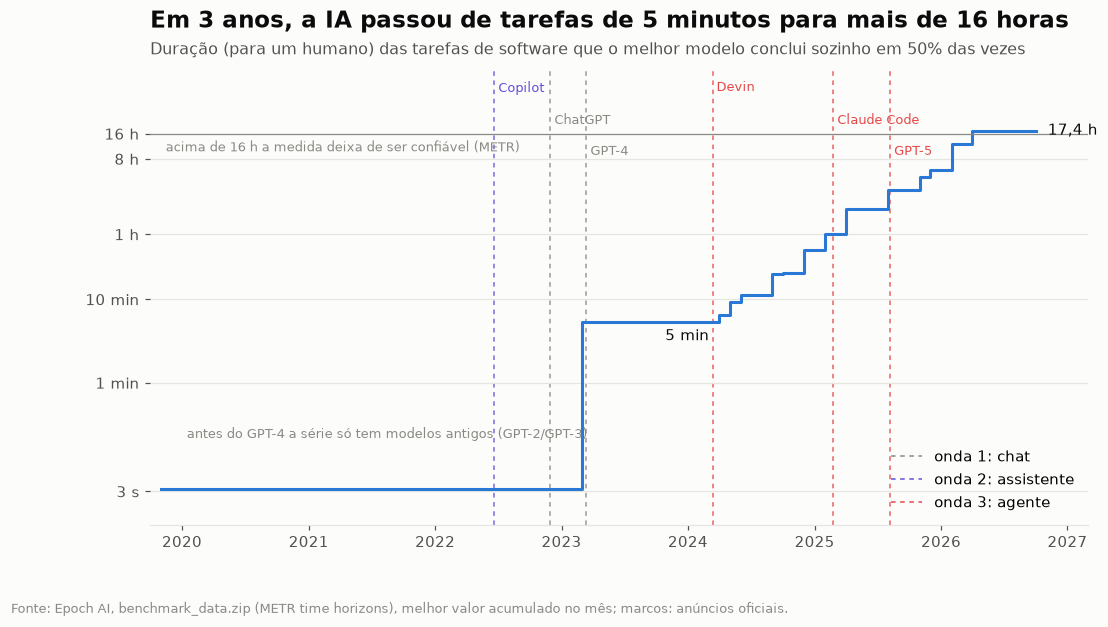

In [7]:
# Gráfico 0: horizonte METR em escala log, com marcos por onda.
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.step(h.index, h.values, where="post", color=DESTAQUE, lw=2)
ax.set_yscale("log")
ax.set_ylim(0.02, 6000)
ticks = [0.05, 1, 10, 60, 480, 960]
ax.set_yticks(ticks, ["3 s", "1 min", "10 min", "1 h", "8 h", "16 h"])
ax.minorticks_off()
ax.set_xlim(pd.Timestamp("2019-10-01"), pd.Timestamp("2027-03-01"))
eixo_tempo(ax, 1)
ax.axhline(960, color=TEXTO_3, lw=0.8)
ax.text(pd.Timestamp("2019-11-15"), 800, "acima de 16 h a medida deixa de ser confiável (METR)",
        fontsize=8.5, color=TEXTO_3, va="top")
marcos(ax, sel_marcos("Copilot", "ChatGPT", "GPT-4", "Devin", "Claude Code", "GPT-5"), y_frac=0.97)
ult = h.iloc[-1]
ax.annotate(f"{num(ult / 60, 1)} h", (h_fim, ult), xytext=(8, 0), textcoords="offset points",
            fontsize=10, color=TEXTO, va="center")
ax.annotate(f"{num(h_3a)} min", (h_fim - pd.DateOffset(years=3), h_3a), xytext=(6, -12),
            textcoords="offset points", fontsize=10, color=TEXTO)
ax.legend(handles=[Line2D([], [], color=CORES_ONDA[k], lw=1, ls=(0, (3, 3)), label=l) for k, l in
                   [("chat", "onda 1: chat"), ("assistente", "onda 2: assistente"), ("agente", "onda 3: agente")]],
          loc="lower right")
titulo(ax, f"Em 3 anos, a IA passou de tarefas de {num(h_3a)} minutos para mais de 16 horas",
       "Duração (para um humano) das tarefas de software que o melhor modelo conclui sozinho em 50% das vezes")
ax.text(pd.Timestamp("2020-01-15"), 0.2, "antes do GPT-4 a série só tem modelos antigos (GPT-2/GPT-3)",
        fontsize=8.5, color=TEXTO_3, va="bottom")
fonte(fig, "Epoch AI, benchmark_data.zip (METR time horizons), melhor valor acumulado no mês; marcos: anúncios oficiais.")
plt.show()

In [8]:
mostrar(f"""
**O que vemos →** o melhor modelo saiu de tarefas de **{num(h_3a)} minutos** em {mes_br(h_fim - pd.DateOffset(years=3))}
para **{num(h.iloc[-1] / 60, 1)} horas** em {mes_br(h_fim)}, e a curva acelera a partir da onda dos agentes.
O METR mede que esse horizonte dobra em intervalos cada vez menores: {fato('metr_doubling').numero}
({cita('metr_doubling', 'Kwa et al.')}).

**O que significa →** a IA deixou de responder dúvidas e passou a entregar tarefas inteiras. Tarefa curta e bem
definida é justamente o que se dava para o júnior. O último ponto passa do limite de {fato('metr_16h').numero}
em que o próprio METR diz que a medida deixa de ser confiável ({cita('metr_16h', 'METR')}), então vale a tendência, não o valor exato.

**O que fazer →** usar esse horizonte como o relógio da história: cada onda (chat, assistente, agente) é um marco nos gráficos seguintes.
""")


**O que vemos →** o melhor modelo saiu de tarefas de **5 minutos** em out/2023
para **17,4 horas** em out/2026, e a curva acelera a partir da onda dos agentes.
O METR mede que esse horizonte dobra em intervalos cada vez menores: ~7 meses (2019-2025); ~131 dias (desde 2023)
([Kwa et al.](https://arxiv.org/abs/2503.14499)).

**O que significa →** a IA deixou de responder dúvidas e passou a entregar tarefas inteiras. Tarefa curta e bem
definida é justamente o que se dava para o júnior. O último ponto passa do limite de 16 h
em que o próprio METR diz que a medida deixa de ser confiável ([METR](https://metr.org/time-horizons/)), então vale a tendência, não o valor exato.

**O que fazer →** usar esse horizonte como o relógio da história: cada onda (chat, assistente, agente) é um marco nos gráficos seguintes.


## 3. Preparar os dados exigiu desarmar duas armadilhas
`CRISP-DM fase 3 | Preparação dos dados` · `ETL: Transform / Load`

O ETL roda em scripts (`src/etl/`) e grava arquivos leves em `data/processed/`. Este notebook só lê o resultado.

- **Só meses completos.** O mês corrente fica de fora, senão a última barra parece uma queda que não aconteceu.
- **Vagas diárias → médias mensais**, com o índice do Indeed (fev/2020 = 100) e a mediana dos outros setores como comparação.
- **Capacidade da IA:** melhor valor acumulado até cada mês (o recorde não "desaprende").
- **Salário:** valores anuais fora de US$ 1 mil a US$ 1 milhão viram ausentes; só EUA, para não misturar moedas e custo de vida.
- **Experiência = anos de trabalho profissional (WorkExp)**, não anos programando. Faixas: até 2 anos, 3 a 9, 10 ou mais.

In [9]:
c = comparab.set_index("coluna")["anos_comparaveis"]
nomes = {"faixa_exp": "faixa de experiência", "empregado": "está empregado", "salario_usd": "salário (US$)",
         "pais": "país", "cargo": "cargo", "ia_usa": "usa IA", "ia_ameaca": "vê a IA como ameaça",
         "usa_agentes": "usa agentes de IA"}
lin = "\n".join(f"| {nomes[k]} | {c[k].replace(';', ', ')} |" for k in nomes
                if k in c.index and c[k][:1].isdigit())
e24 = emp[(emp.ano == 2024) & (emp.faixa_exp == "≤2") & (emp.metodo == "bruto")].iloc[0]
e25 = emp[(emp.ano == 2025) & (emp.faixa_exp == "≤2") & (emp.metodo == "bruto")].iloc[0]
mostrar(f"""
**Harmonização do survey.** As perguntas mudam de nome e de formato a cada ano. Só comparamos entre anos o que foi
perguntado do mesmo jeito:

| Variável | Anos comparáveis |
|---|---|
{lin}

**Armadilha 1: seleção na pergunta de experiência.** Em 2024, {pct(e24.pct_empregado * 100)} de quem tinha até 2 anos
aparecia como empregado. Parecia ótimo, até a gente ver que a pergunta de experiência foi respondida quase só por quem
trabalha. Em 2025 a mesma faixa mostra {pct(e25.pct_empregado * 100)}. 2023 e 2024 ficaram fora da comparação de emprego.

**Armadilha 2: "usa agentes" mudou de definição** entre 2025 (pergunta própria) e 2026 (uma opção dentro de outra
pergunta). Por isso só comparamos júnior com sênior dentro do mesmo ano, nunca 2025 com 2026.
""")


**Harmonização do survey.** As perguntas mudam de nome e de formato a cada ano. Só comparamos entre anos o que foi
perguntado do mesmo jeito:

| Variável | Anos comparáveis |
|---|---|
| faixa de experiência | 2023, 2024, 2025, 2026 |
| está empregado | 2023, 2024, 2025, 2026 |
| salário (US$) | 2023, 2024, 2025, 2026 |
| país | 2023, 2024, 2025, 2026 |
| cargo | 2023, 2024, 2025 |
| usa IA | 2023, 2024, 2025 |
| vê a IA como ameaça | 2024, 2025 |

**Armadilha 1: seleção na pergunta de experiência.** Em 2024, 97% de quem tinha até 2 anos
aparecia como empregado. Parecia ótimo, até a gente ver que a pergunta de experiência foi respondida quase só por quem
trabalha. Em 2025 a mesma faixa mostra 62%. 2023 e 2024 ficaram fora da comparação de emprego.

**Armadilha 2: "usa agentes" mudou de definição** entre 2025 (pergunta própria) e 2026 (uma opção dentro de outra
pergunta). Por isso só comparamos júnior com sênior dentro do mesmo ano, nunca 2025 com 2026.


## 4. Primeiro esvaziou o lugar onde se aprendia; depois, as vagas
`EDA | análise exploratória`

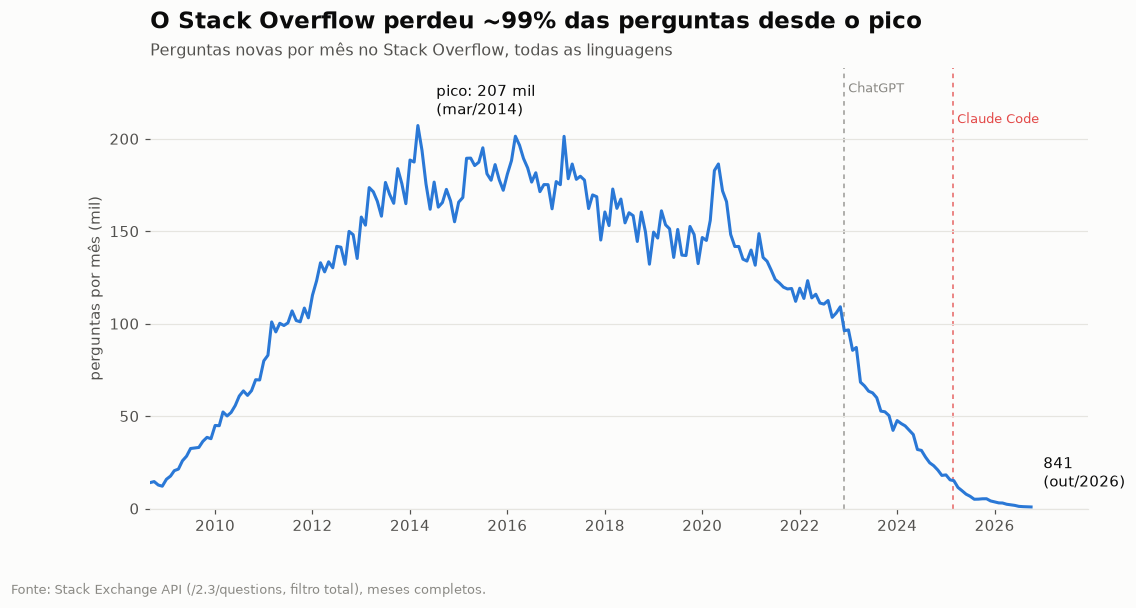

In [10]:
# Gráfico 1: Stack Overflow, série total.
fig, ax = plt.subplots()
ax.plot(so_total.index, so_total / 1000, color=DESTAQUE)
ax.set_ylim(0, so_pico / 1000 * 1.15)
ax.set_ylabel("perguntas por mês (mil)")
eixo_tempo(ax, 2)
ax.set_xlim(so_total.index.min(), so_total.index.max() + pd.DateOffset(months=14))
marcos(ax, sel_marcos("ChatGPT", "Claude Code"), y_frac=0.97)
ax.annotate(f"pico: {num(so_pico / 1000)} mil\n({mes_br(so_pico_mes)})", (so_pico_mes, so_pico / 1000),
            xytext=(12, 4), textcoords="offset points", fontsize=10, color=TEXTO, va="bottom")
ax.annotate(f"{num(so_ult)}\n({mes_br(so_ult_mes)})", (so_ult_mes, so_ult / 1000), xytext=(8, 10),
            textcoords="offset points", fontsize=10, color=TEXTO, va="bottom")
titulo(ax, f"O Stack Overflow perdeu ~{math.floor(so_queda)}% das perguntas desde o pico",
       "Perguntas novas por mês no Stack Overflow, todas as linguagens")
fonte(fig, "Stack Exchange API (/2.3/questions, filtro total), meses completos.")
plt.show()

In [11]:
p23 = so_total.loc["2022-11-01"]
mostrar(f"""
**O que vemos →** a queda começa antes da IA (o site já perdia fôlego desde {so_pico_mes.year}), mas acelera depois do
ChatGPT: de {num(p23 / 1000)} mil perguntas em nov/2022 para {num(so_ult)} em {mes_br(so_ult_mes)}.

**O que significa →** o Stack Overflow era onde o iniciante tirava dúvida em público e aprendia vendo a dúvida dos outros.
Esse espaço quase sumiu. Um estudo com plataformas-controle achou queda de {lit('pnas_25')} só nos primeiros
6 meses após o ChatGPT, e os autores tratam isso como piso ({cita('pnas_25', 'del Rio-Chanona et al., PNAS Nexus')}).

**O que fazer →** não dá para atribuir tudo à IA só olhando a curva, porque ela já caía. Na seção 5 comparamos com uma projeção do que seria sem IA.
""")


**O que vemos →** a queda começa antes da IA (o site já perdia fôlego desde 2014), mas acelera depois do
ChatGPT: de 109 mil perguntas em nov/2022 para 841 em out/2026.

**O que significa →** o Stack Overflow era onde o iniciante tirava dúvida em público e aprendia vendo a dúvida dos outros.
Esse espaço quase sumiu. Um estudo com plataformas-controle achou queda de 25% só nos primeiros
6 meses após o ChatGPT, e os autores tratam isso como piso ([del Rio-Chanona et al., PNAS Nexus](https://pmc.ncbi.nlm.nih.gov/articles/PMC11421660/)).

**O que fazer →** não dá para atribuir tudo à IA só olhando a curva, porque ela já caía. Na seção 5 comparamos com uma projeção do que seria sem IA.


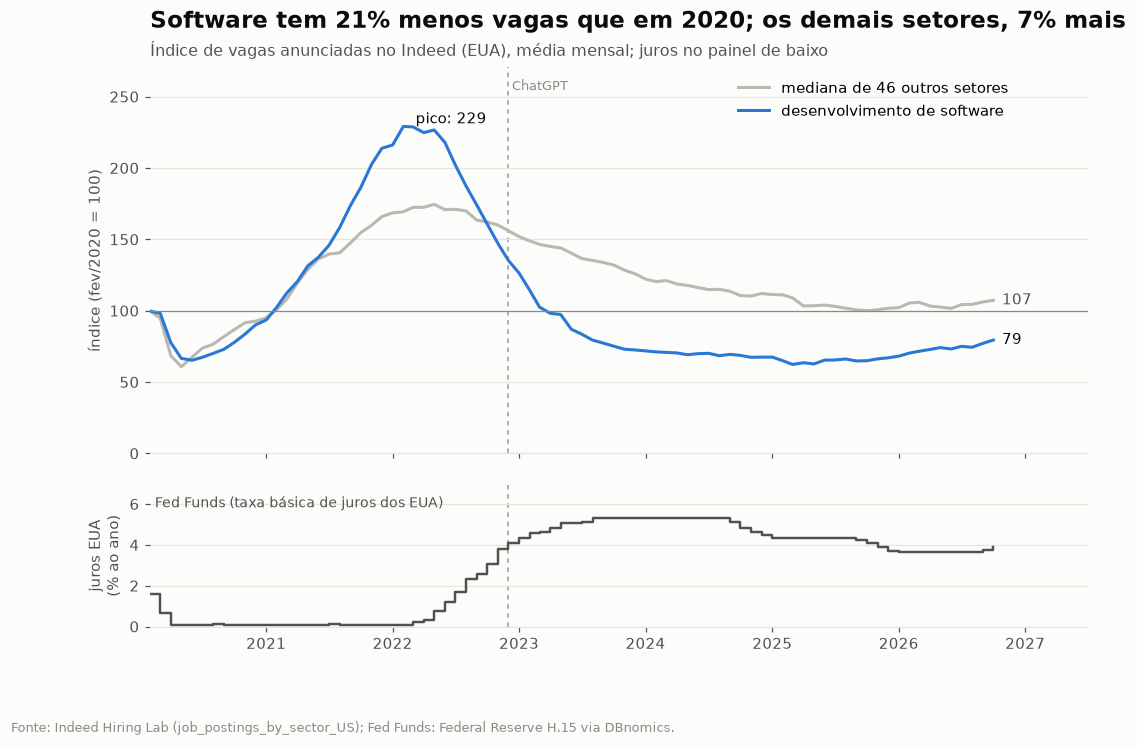

In [12]:
# Gráfico 2: vagas (índice fev/2020 = 100) e juros em painel separado.
fig, (a1x, a2x) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1.1], "hspace": 0.12})
a1x.plot(vs_serie.index, vs_serie.mediana_setores, color=CONTEXTO, label=f"mediana de {VAGAS['n_setores_outros']} outros setores")
a1x.plot(vs_serie.index, vs_serie.software, color=DESTAQUE, label="desenvolvimento de software")
a1x.axhline(100, color=TEXTO_3, lw=0.8)
a1x.set_ylabel("índice (fev/2020 = 100)")
a1x.set_ylim(0, vs_serie.software.max() * 1.18)
a1x.set_xlim(vs_serie.index.min(), vs_serie.index.max() + pd.DateOffset(months=9))
eixo_tempo(a1x, 1)
pk = pd.Timestamp(VAGAS["pico_software"]["mes"])
a1x.annotate(f"pico: {num(VAGAS['pico_software']['indice'])}", (pk, VAGAS["pico_software"]["indice"]),
             xytext=(8, 2), textcoords="offset points", fontsize=10, color=TEXTO)
rotulo_final(a1x, vs_serie.software, num(desc["software_ultimo"]), cor=TEXTO, dx_dias=25)
rotulo_final(a1x, vs_serie.mediana_setores, num(desc["mediana_ultimo"]), cor=TEXTO_2, dx_dias=25)
a1x.legend(loc="upper right", bbox_to_anchor=(0.93, 1.0))
marcos(a1x, sel_marcos("ChatGPT"), y_frac=0.97)
fed = vs_serie.FEDFUNDS
a2x.step(fed.index, fed, where="post", color=TEXTO_2, lw=1.6)
a2x.set_ylabel("juros EUA\n(% ao ano)")
a2x.set_ylim(0, fed.max() * 1.3)
marcos(a2x, sel_marcos("ChatGPT"), rotulos=False)
a2x.text(0.005, 0.92, "Fed Funds (taxa básica de juros dos EUA)", transform=a2x.transAxes, fontsize=9,
         color=TEXTO_2, va="top")
sw_var, md_var = desc["software_ultimo"] - 100, desc["mediana_ultimo"] - 100
qual = lambda v: "menos" if v < 0 else "mais"
titulo(a1x, f"Software tem {pct(abs(sw_var))} {qual(sw_var)} vagas que em 2020; os demais setores, {pct(abs(md_var))} {qual(md_var)}",
       "Índice de vagas anunciadas no Indeed (EUA), média mensal; juros no painel de baixo")
fonte(fig, "Indeed Hiring Lab (job_postings_by_sector_US); Fed Funds: Federal Reserve H.15 via DBnomics.")
plt.show()

In [13]:
mostrar(f"""
**O que vemos →** software subiu muito mais no boom (pico de {num(VAGAS['pico_software']['indice'])} em
{mes_br(VAGAS['pico_software']['mes'])}) e caiu muito mais depois. Hoje está em {num(desc['software_ultimo'])}, contra
{num(desc['mediana_ultimo'])} da mediana dos outros setores. A queda coincide com a alta dos juros, que começou em 2022.

**O que significa →** o gráfico é compatível com as duas histórias: a IA reduzindo vagas e o fim de um boom financiado por
juro zero. O Indeed registra o mesmo patamar: vagas de software {lit('indeed_275')} abaixo de fev/2020
({cita('indeed_275', 'Indeed Hiring Lab')}). Só o desenho não separa as duas.

**O que fazer →** testar com um modelo que coloque os juros dentro da conta (Ato 2).
""")


**O que vemos →** software subiu muito mais no boom (pico de 229 em
fev/2022) e caiu muito mais depois. Hoje está em 79, contra
107 da mediana dos outros setores. A queda coincide com a alta dos juros, que começou em 2022.

**O que significa →** o gráfico é compatível com as duas histórias: a IA reduzindo vagas e o fim de um boom financiado por
juro zero. O Indeed registra o mesmo patamar: vagas de software 27,5% abaixo de fev/2020
([Indeed Hiring Lab](https://hiringlab.indeed.com/?p=20708)). Só o desenho não separa as duas.

**O que fazer →** testar com um modelo que coloque os juros dentro da conta (Ato 2).


## 5. Os modelos confirmam o júnior encolhendo; o motivo nas vagas continua aberto
`CRISP-DM fase 4 | Modelagem` · `Análise preditiva`

### Ato 1: o Stack Overflow ficou muito abaixo do que se esperaria sem IA
Treinamos um SARIMAX (série temporal com sazonalidade) com as perguntas de 2014 até out/2022 e projetamos o que viria
depois se nada tivesse mudado. A distância entre o real e a projeção é o efeito estimado.

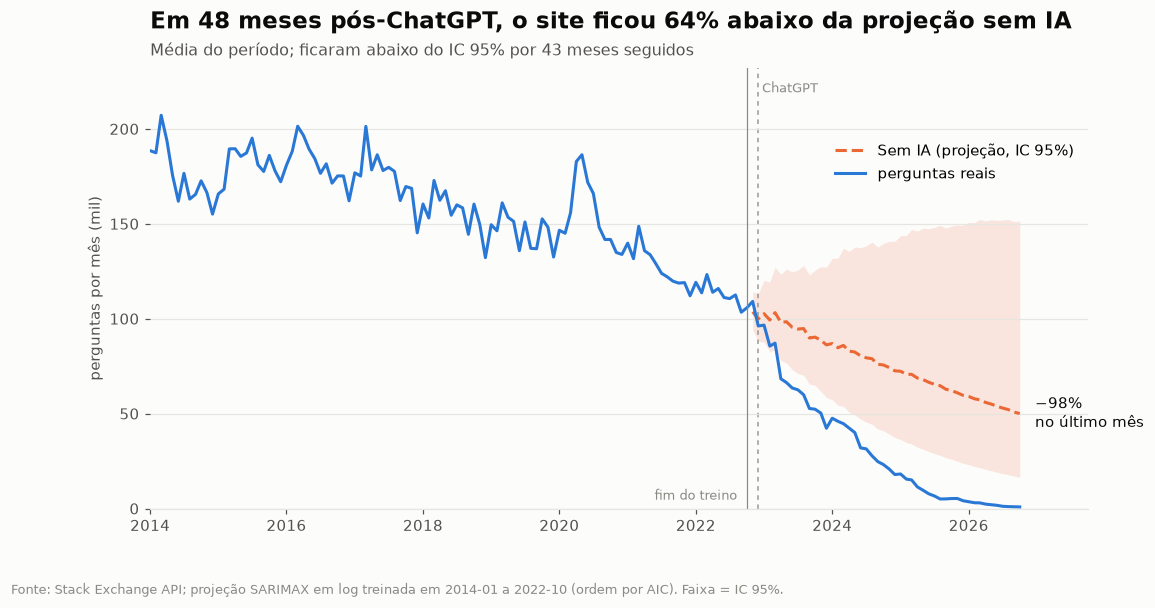

In [14]:
# Gráfico 3: real vs. contrafactual SARIMAX.
real = so_total.loc["2014-01-01":]
fig, ax = plt.subplots()
faixa_ic(ax, cf / 1000)
ax.plot(real.index, real / 1000, color=DESTAQUE, label="perguntas reais")
ax.axvline(pd.Timestamp(A1["modelo"]["treino_fim"]), color=TEXTO_3, lw=0.8)
ax.text(pd.Timestamp(A1["modelo"]["treino_fim"]) - pd.Timedelta(days=30), 3, "fim do treino ",
        fontsize=8.5, color=TEXTO_3, ha="right", va="bottom")
ax.set_ylim(0, real.max() / 1000 * 1.12)
ax.set_xlim(real.index.min(), real.index.max() + pd.DateOffset(months=12))
ax.set_ylabel("perguntas por mês (mil)")
eixo_tempo(ax, 2)
marcos(ax, sel_marcos("ChatGPT"), y_frac=0.97)
lm = cf.index[-1]
ax.annotate(f"{pct(e48['efeito_pct_ultimo_mes'])}\nno último mês", (lm, cf.previsto.iloc[-1] / 1000),
            xytext=(10, 0), textcoords="offset points", fontsize=10, color=TEXTO, va="center")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.86))
titulo(ax, f"Em {e48['n_meses']} meses pós-ChatGPT, o site ficou {pct(-e48['efeito_pct_medio'])} abaixo da projeção sem IA",
       f"Média do período; ficaram abaixo do IC 95% por {e48['meses_abaixo_ic_seguidos']} meses seguidos")
fonte(fig, "Stack Exchange API; projeção SARIMAX em log treinada em 2014-01 a 2022-10 (ordem por AIC). Faixa = IC 95%.")
plt.show()

In [15]:
pl = A1["comparacao_placebo_principal"]
if A1["veredito"] == "efeito sustentado":
    leitura = "Pela regra combinada antes, o efeito é **sustentado**: nenhum placebo chega perto."
else:
    leitura = (f"Pela regra combinada antes, o veredito é **inconclusivo**. A regra compara o primeiro ano depois do ChatGPT "
               f"({pct(pl['efeito_real_12m_pct'])}) com placebos de 12 meses, e o placebo de jun/2020, quando o pico da "
               f"COVID se desfez, deu {pct(-pl['max_abs_placebo_pct'])}. Em {e48['n_meses']} meses nenhum placebo dura nem se "
               f"aproxima de {pct(e48['efeito_pct_medio'])}, mas essa leitura não estava na regra, então não muda o veredito.")
mostrar(f"""
**O que vemos →** até out/2022 o modelo acompanha bem a série (erra {num(A1['backtest']['mape_modelo_medio'], 1)}% em média
no passado, contra {num(A1['backtest']['mape_ingenuo_medio'], 1)}% de um ingênuo sazonal). Depois disso o real descola para
baixo e não volta.

**O que significa →** {leitura}

**O que fazer →** tratar o esvaziamento do Stack Overflow como forte sinal, não como prova. Ele mede perguntas no site,
não empregos; parte da queda é o chatbot substituindo o fórum.
""")


**O que vemos →** até out/2022 o modelo acompanha bem a série (erra 9,9% em média
no passado, contra 13,8% de um ingênuo sazonal). Depois disso o real descola para
baixo e não volta.

**O que significa →** Pela regra combinada antes, o veredito é **inconclusivo**. A regra compara o primeiro ano depois do ChatGPT (−24%) com placebos de 12 meses, e o placebo de jun/2020, quando o pico da COVID se desfez, deu −30%. Em 48 meses nenhum placebo dura nem se aproxima de −64%, mas essa leitura não estava na regra, então não muda o veredito.

**O que fazer →** tratar o esvaziamento do Stack Overflow como forte sinal, não como prova. Ele mede perguntas no site,
não empregos; parte da queda é o chatbot substituindo o fórum.


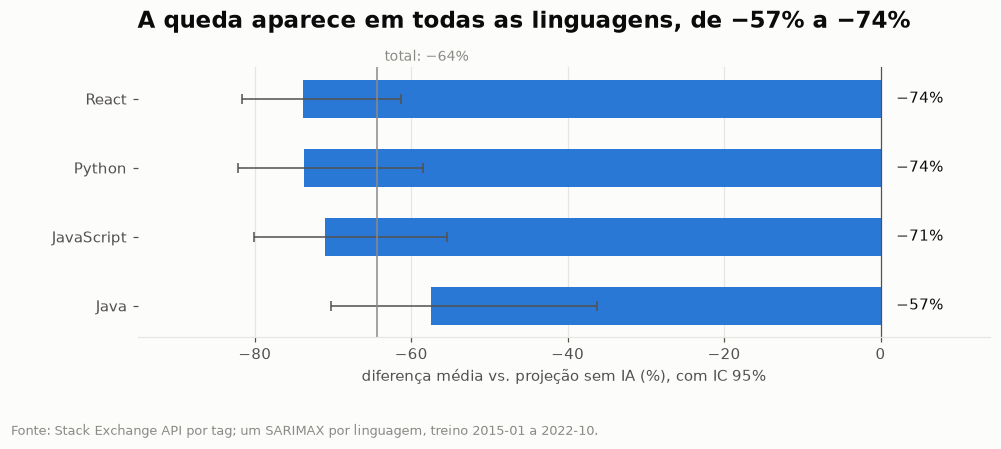


**O que vemos →** nenhuma linguagem escapa. A que menos cai é Java (−57%), e todas
ficam abaixo do intervalo da projeção por pelo menos 43 meses seguidos.

**O que significa →** não é o declínio de uma tecnologia; o que mudou foi o hábito de perguntar no fórum.

**O que fazer →** usar isso como robustez do Ato 1, não como argumento separado.


In [16]:
# Gráfico 4 (pequeno): efeito por linguagem.
nomes_tag = {"python": "Python", "javascript": "JavaScript", "java": "Java", "reactjs": "React"}
t = tags.assign(nome=tags.tag.map(nomes_tag)).sort_values("efeito_pct_medio", ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.6))
fig.subplots_adjust(bottom=0.2)
ax.set_axisbelow(True)
y = np.arange(len(t))
ax.barh(y, t.efeito_pct_medio, color=DESTAQUE, height=0.55)
ax.errorbar(t.efeito_pct_medio, y, xerr=[t.efeito_pct_medio - t.efeito_pct_lo, t.efeito_pct_hi - t.efeito_pct_medio],
            fmt="none", ecolor=TEXTO_2, elinewidth=1, capsize=3)
for yi, v in zip(y, t.efeito_pct_medio):
    ax.text(2, yi, pct(v), va="center", ha="left", fontsize=10, color=TEXTO)
ax.axvline(e48["efeito_pct_medio"], color=TEXTO_3, lw=1)
ax.text(e48["efeito_pct_medio"] + 1, len(t) - 0.45, f"total: {pct(e48['efeito_pct_medio'])}", fontsize=9, color=TEXTO_3)
ax.set_yticks(y, t.nome)
ax.set_xlim(-95, 14)
ax.axvline(0, color=TEXTO_2, lw=0.8)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("diferença média vs. projeção sem IA (%), com IC 95%")
titulo(ax, f"A queda aparece em todas as linguagens, de {pct(t.efeito_pct_medio.max())} a {pct(t.efeito_pct_medio.min())}")
fonte(fig, "Stack Exchange API por tag; um SARIMAX por linguagem, treino 2015-01 a 2022-10.")
plt.show()
mostrar(f"""
**O que vemos →** nenhuma linguagem escapa. A que menos cai é {t.nome.iloc[0]} ({pct(t.efeito_pct_medio.iloc[0])}), e todas
ficam abaixo do intervalo da projeção por pelo menos {t.meses_abaixo_ic_seguidos.min()} meses seguidos.

**O que significa →** não é o declínio de uma tecnologia; o que mudou foi o hábito de perguntar no fórum.

**O que fazer →** usar isso como robustez do Ato 1, não como argumento separado.
""")

In [17]:
if "ciclo" in A2["veredito"]:
    t2 = "software caiu mais que os outros setores, mas o modelo não consegue separar IA do fim do boom"
else:
    t2 = "software caiu mais que os outros setores mesmo descontando os juros"
mostrar(f"""### Ato 2: {t2}
Modelamos a razão entre o índice de vagas de software e a mediana dos outros setores (em log) com duas explicações
ao mesmo tempo: a taxa de juros (o ciclo) e um marcador "depois do ChatGPT" (dez/2022 em diante).""")

### Ato 2: software caiu mais que os outros setores, mas o modelo não consegue separar IA do fim do boom
Modelamos a razão entre o índice de vagas de software e a mediana dos outros setores (em log) com duas explicações
ao mesmo tempo: a taxa de juros (o ciclo) e um marcador "depois do ChatGPT" (dez/2022 em diante).

In [18]:
def linha_coef(m, termo, rotulo):
    c = m["coeficientes"][termo]
    ic = c.get("ic95", [np.nan, np.nan])
    return (f"| {rotulo} | {num(c['coef'], 3)} | {pct(c.get('efeito_pct', np.nan), 1, True)} | "
            f"{num(ic[0], 3)} a {num(ic[1], 3)} | {'< 0,001' if c['p'] < 0.001 else num(c['p'], 3)} |")

def tabela_modelo(m):
    cab = "| Termo | Coeficiente (log) | Efeito aprox. | IC 95% | p |\n|---|---|---|---|---|\n"
    return cab + "\n".join([linha_coef(m, "pos", "depois do ChatGPT"), linha_coef(m, "FEDFUNDS", "Fed Funds (+1 p.p.)")])

ar1 = A2_PRINC.get("ar1")
desc_m = "regressão com erros AR(1)" if ar1 is not None else "regressão com erros HAC"
txt = f"""**Modelo principal: {desc_m}** ({A2_PRINC.get('n', VAGAS['n_meses'])} meses, de {mes_br(VAGAS['inicio'])} a {mes_br(VAGAS['fim'])}).
Alvo: log(vagas de software ÷ mediana dos outros setores).

{tabela_modelo(A2_PRINC)}

**Veredito: {ICONE.get(A2['veredito'], A2['veredito'])}.** {A2['explicacao']}
"""
if A2_HAC is not None:
    txt += f"""
*Modelo inicial, substituído.* A primeira versão era uma regressão comum com erros HAC. Ela dava o marcador "depois do
ChatGPT" em {pct(A2_HAC['coeficientes']['pos']['efeito_pct'], 0, True)} com p < 0,001, o que passaria na regra. A revisão
achou os resíduos muito autocorrelacionados (Durbin-Watson {num(A2_HAC['durbin_watson'], 2)}; correlação de um mês com o
seguinte de {num(A2_HAC['autocorr_lag1'], 2)}), e com tão poucos meses o HAC não dá conta disso: o p-valor saía otimista demais.
No modelo AR(1) cada mês carrega {pct(ar1 * 100)} do desvio do mês anterior; com essa inércia na conta, o efeito do marcador
encolhe para {pct(A2_PRINC['coeficientes']['pos']['efeito_pct'], 1, True)} e deixa de ser significativo.
"""
ph = VAGAS["sensibilidade_pos_hoc"]["placebos_dummy"]
txt += f"""
**O porém do boom.** Juros e marcador andam quase juntos (correlação de {num(VAGAS.get('corr_fedfunds_pos', np.nan), 2)}), e o
período antes do ChatGPT tem só {meses_pre_vagas} meses, quase todos de boom. No modelo antigo, pôr o marcador em datas
falsas ({', '.join(mes_br(p['dummy_desde']) for p in ph)}) também gerava saltos grandes
({', '.join(pct(p['efeito_pct'], 0, True) for p in ph)}). Esta checagem foi feita depois de ver o resultado e não entra no veredito.
"""
mostrar(txt)

**Modelo principal: regressão com erros AR(1)** (81 meses, de fev/2020 a out/2026).
Alvo: log(vagas de software ÷ mediana dos outros setores).

| Termo | Coeficiente (log) | Efeito aprox. | IC 95% | p |
|---|---|---|---|---|
| depois do ChatGPT | −0,033 | −3,3% | −0,185 a 0,119 | 0,668 |
| Fed Funds (+1 p.p.) | −0,096 | −9,2% | −0,129 a −0,063 | < 0,001 |

**Veredito: ○ Consistente com ciclo.** Software caiu mais que os outros setores depois de 2022, mas quando se modela a inércia da série e os juros, a diferença não se separa do fim do boom de 2021–22; os dados não permitem atribuir à IA.

*Modelo inicial, substituído.* A primeira versão era uma regressão comum com erros HAC. Ela dava o marcador "depois do
ChatGPT" em −28% com p < 0,001, o que passaria na regra. A revisão
achou os resíduos muito autocorrelacionados (Durbin-Watson 0,20; correlação de um mês com o
seguinte de 0,90), e com tão poucos meses o HAC não dá conta disso: o p-valor saía otimista demais.
No modelo AR(1) cada mês carrega 96% do desvio do mês anterior; com essa inércia na conta, o efeito do marcador
encolhe para −3,3% e deixa de ser significativo.

**O porém do boom.** Juros e marcador andam quase juntos (correlação de 0,93), e o
período antes do ChatGPT tem só 34 meses, quase todos de boom. No modelo antigo, pôr o marcador em datas
falsas (jun/2021, mar/2022, jun/2022) também gerava saltos grandes
(+25%, +30%, +25%). Esta checagem foi feita depois de ver o resultado e não entra no veredito.


In [19]:
if "ciclo" not in A2["veredito"]:
    mostrar(f"""
**O que vemos →** mesmo com juros e inércia no modelo, software ficou {pct(A2_PRINC['coeficientes']['pos']['efeito_pct'], 1, True)}
abaixo dos outros setores depois do ChatGPT. **O que significa →** é consistente com IA, mas o período antes do ChatGPT tem
só {meses_pre_vagas} meses e é dominado pelo boom. **O que fazer →** tratar como indício, junto com o survey (Ato 3).
""")
else:
    mostrar(f"""
**O que vemos →** software caiu mais que os outros setores depois de 2022. Mas, quando o modelo leva em conta a inércia
da série e os juros, o marcador "depois do ChatGPT" fica em {pct(A2_PRINC['coeficientes']['pos']['efeito_pct'], 1, True)}
(p = {num(A2_PRINC['coeficientes']['pos']['p'], 2)}); os juros continuam pesando
({pct(A2_PRINC['coeficientes']['FEDFUNDS']['efeito_pct'], 1, True)} por ponto de Fed Funds).

**O que significa →** este é o ponto mais fraco da nossa tese, e preferimos mostrar. Com {meses_pre_vagas} meses de dados
antes do ChatGPT, quase todos de boom, os dados não distinguem "IA" de "ressaca do boom com juros altos". Para vagas, a
tese rival (ciclo) explica tão bem quanto a nossa.

**O que fazer →** não usar o gráfico de vagas como prova de que a IA tirou empregos. A evidência mais direta sobre o júnior vem do survey, no Ato 3.
""")


**O que vemos →** software caiu mais que os outros setores depois de 2022. Mas, quando o modelo leva em conta a inércia
da série e os juros, o marcador "depois do ChatGPT" fica em −3,3%
(p = 0,67); os juros continuam pesando
(−9,2% por ponto de Fed Funds).

**O que significa →** este é o ponto mais fraco da nossa tese, e preferimos mostrar. Com 34 meses de dados
antes do ChatGPT, quase todos de boom, os dados não distinguem "IA" de "ressaca do boom com juros altos". Para vagas, a
tese rival (ciclo) explica tão bem quanto a nossa.

**O que fazer →** não usar o gráfico de vagas como prova de que a IA tirou empregos. A evidência mais direta sobre o júnior vem do survey, no Ato 3.


### Ato 3 (H1): quem está começando perdeu emprego muito mais rápido que o sênior
O survey do Stack Overflow pergunta a situação de emprego e os anos de experiência. Comparamos 2025 com 2026 por três
métodos, porque quem responde a pergunta de experiência mudou de um ano para o outro: (1) bruto; (2) reponderado pela
chance de responder (IPW); (3) só quem tem exatamente 2 anos, que é menos afetado pelo acúmulo de respostas em "1 ano".

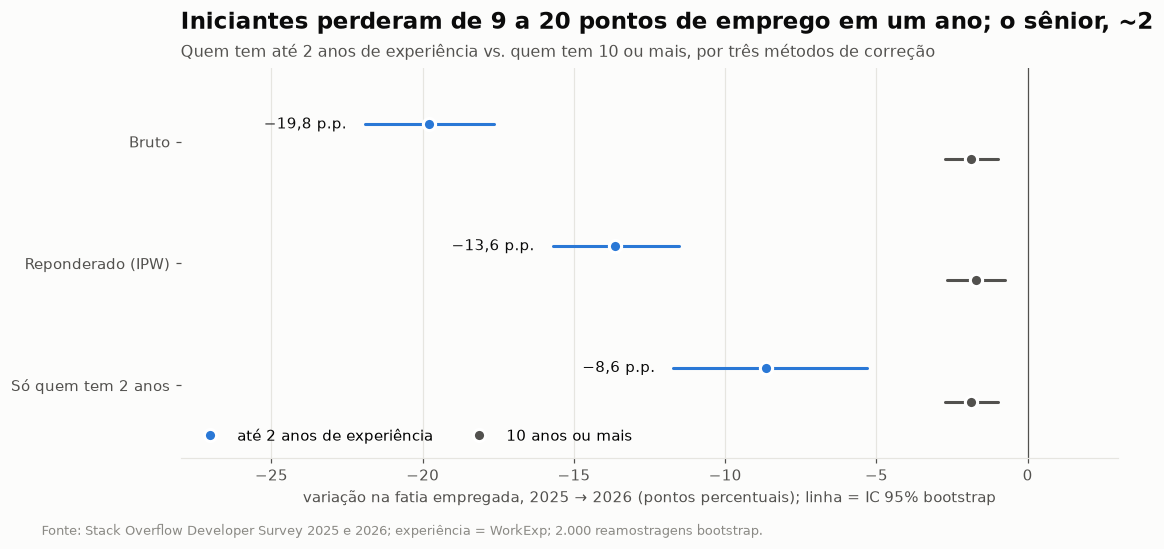

In [20]:
# Gráfico 5: variação da % empregada 2025 → 2026, ≤2 vs ≥10, três métodos, com IC 95%.
rot_met = {"bruto": "Bruto", "ipw": "Reponderado (IPW)", "workexp_igual_2": "Só quem tem 2 anos"}
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (k, rot) in enumerate(rot_met.items()):
    yy = len(rot_met) - 1 - i
    for chave, dy, cor, lab in [("variacao_jr", 0.14, DESTAQUE, "até 2 anos de experiência"),
                                ("variacao_sr", -0.14, TEXTO_2, "10 anos ou mais")]:
        v = emp_m[k][chave]
        est, lo, hi = v["estimativa"] * 100, v["ic_inf"] * 100, v["ic_sup"] * 100
        ax.plot([lo, hi], [yy + dy] * 2, color=cor, lw=2, solid_capstyle="round")
        ax.plot(est, yy + dy, "o", color=cor, ms=8, mec="white", mew=2, label=lab if i == 0 else None)
        if chave == "variacao_jr":
            ax.text(lo - 0.6, yy + dy, pp(v["estimativa"]), ha="right", va="center", fontsize=10, color=TEXTO)
ax.set_yticks(range(len(rot_met)), list(rot_met.values())[::-1])
ax.axvline(0, color=TEXTO_2, lw=0.8)
ax.set_xlim(-28, 3)
ax.set_ylim(-0.6, len(rot_met) - 0.4)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("variação na fatia empregada, 2025 → 2026 (pontos percentuais); linha = IC 95% bootstrap")
ax.legend(loc="lower left", ncols=2)
titulo(ax, f"Iniciantes perderam de {num(jr_max)} a {num(jr_min)} pontos de emprego em um ano; o sênior, ~{num(sr_var)}",
       "Quem tem até 2 anos de experiência vs. quem tem 10 ou mais, por três métodos de correção")
fonte(fig, "Stack Overflow Developer Survey 2025 e 2026; experiência = WorkExp; 2.000 reamostragens bootstrap.")
plt.show()

In [21]:
rb = H1["numeros"]["emprego"]["robustez_jr_sem_estudantes"]
e26 = emp[(emp.ano == 2026) & (emp.faixa_exp == "≤2") & (emp.metodo == "bruto")].iloc[0]
e25s = emp[(emp.ano == 2025) & (emp.faixa_exp == "≤2") & (emp.metodo == "bruto")].iloc[0]
c19 = fato("canaries_19"); hl = fato("hl_efeito")
mostrar(f"""
**O que vemos →** nos três métodos a queda do júnior é grande e o intervalo fica longe do zero; a do sênior é pequena.
Tirando os estudantes da conta, a queda do júnior continua ({pp(rb['variacao']['estimativa'])}).
Veredito de H1 pelo survey: **{ICONE.get(H1['veredito'], H1['veredito'])}**.

**O que significa →** é consistente com o primeiro degrau encolhendo, e bate com estudos independentes: nos EUA, o emprego
de jovens de 22 a 25 anos em ocupações expostas à IA está {c19.numero.lstrip('-')} abaixo do de pares menos expostos
({cita('canaries_19', 'Brynjolfsson, Chandar e Chen')}); em empresas que adotaram IA generativa, o emprego júnior cai
cerca de {hl.numero.split(' ')[0].lstrip('-')} em seis trimestres enquanto o sênior segue igual ({cita('hl_efeito', 'Hosseini e Lichtinger')}).
Cuidado: a amostra de 2026 tem mais estudantes entre os iniciantes ({pct(e26.pct_so_estudante * 100)} contra
{pct(e25s.pct_so_estudante * 100)} em 2025) e quem responde o survey se autosseleciona. É associação, não causa.

**O que fazer →** este é o indicador a acompanhar no survey de 2027: se a distância entre júnior e sênior persistir, a tese ganha força.
""")


**O que vemos →** nos três métodos a queda do júnior é grande e o intervalo fica longe do zero; a do sênior é pequena.
Tirando os estudantes da conta, a queda do júnior continua (−14,3 p.p.).
Veredito de H1 pelo survey: **● Confirmada**.

**O que significa →** é consistente com o primeiro degrau encolhendo, e bate com estudos independentes: nos EUA, o emprego
de jovens de 22 a 25 anos em ocupações expostas à IA está 19% abaixo do de pares menos expostos
([Brynjolfsson, Chandar e Chen](https://digitaleconomy.stanford.edu/app/uploads/2026/08/Canaries_August2026.pdf)); em empresas que adotaram IA generativa, o emprego júnior cai
cerca de 9% em seis trimestres enquanto o sênior segue igual ([Hosseini e Lichtinger](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5425555)).
Cuidado: a amostra de 2026 tem mais estudantes entre os iniciantes (36% contra
22% em 2025) e quem responde o survey se autosseleciona. É associação, não causa.

**O que fazer →** este é o indicador a acompanhar no survey de 2027: se a distância entre júnior e sênior persistir, a tese ganha força.


### H3: o mercado ficou mais exigente, e quem usa agentes se sente *mais* ameaçado

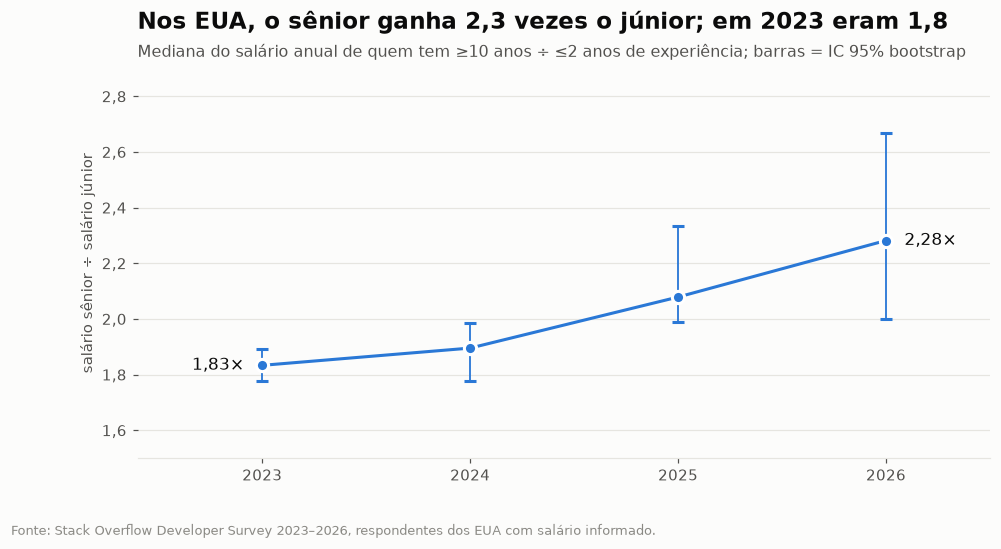

In [22]:
# Gráfico 6: razão salarial sênior/júnior nos EUA, com IC 95%.
fig, ax = plt.subplots(figsize=(10, 4.6))
anos = g.index.values
ax.errorbar(anos, g.razao_sr_jr, yerr=[g.razao_sr_jr - g.razao_ic_inf, g.razao_ic_sup - g.razao_sr_jr],
            fmt="o-", color=DESTAQUE, ecolor=DESTAQUE, elinewidth=1.2, capsize=4, ms=8, mec="white", mew=2, lw=2)
for a, dx, ha in ((a0, -12, "right"), (a1, 12, "left")):
    ax.annotate(f"{num(g.loc[a, 'razao_sr_jr'], 2)}×", (a, g.loc[a, "razao_sr_jr"]), xytext=(dx, 0),
                textcoords="offset points", fontsize=11, color=TEXTO, va="center", ha=ha)
virgula(ax, "y", 1)
ax.set_xticks(anos, [str(a) for a in anos])
ax.set_xlim(a0 - 0.6, a1 + 0.5)
ax.set_ylim(1.5, max(2.9, g.razao_ic_sup.max() * 1.05))
ax.set_ylabel("salário sênior ÷ salário júnior")
titulo(ax, f"Nos EUA, o sênior ganha {num(g.loc[a1, 'razao_sr_jr'], 1)} vezes o júnior; em {a0} eram {num(g.loc[a0, 'razao_sr_jr'], 1)}",
       "Mediana do salário anual de quem tem ≥10 anos ÷ ≤2 anos de experiência; barras = IC 95% bootstrap")
fonte(fig, "Stack Overflow Developer Survey 2023–2026, respondentes dos EUA com salário informado.")
plt.show()

In [23]:
tx = CLF["taxas_descritivas"]
ag = agentes.set_index(["ano", "faixa_exp"])
m = CLF["metricas"]
mostrar(f"""
**O que vemos →** a mediana do júnior caiu de US$ {num(g.loc[a0, 'mediana_jr'] / 1000)} mil para US$ {num(g.loc[a1, 'mediana_jr'] / 1000, 1)} mil
e a do sênior subiu de US$ {num(g.loc[a0, 'mediana_sr'] / 1000)} mil para US$ {num(g.loc[a1, 'mediana_sr'] / 1000)} mil.
A razão aumentou {num(H3['numeros']['gap_salarial']['variacao_razao']['estimativa'], 2)} (IC 95%:
{num(H3['numeros']['gap_salarial']['variacao_razao']['ic_inf'], 2)} a {num(H3['numeros']['gap_salarial']['variacao_razao']['ic_sup'], 2)}).
Em 2026, {pct(ag.loc[(2026, '≥10'), 'pct_usa_agentes'] * 100)} dos sêniores usam agentes de IA, contra
{pct(ag.loc[(2026, '≤2'), 'pct_usa_agentes'] * 100)} dos juniores; em 2025 as faixas empatavam (≈{pct(ag.loc[(2025, '≤2'), 'pct_usa_agentes'] * 100)}).

**O classificador.** Treinamos um modelo para prever quem diz que a IA ameaça seu emprego (survey {CLF['ano']},
{num(CLF['n'])} pessoas, {pct(CLF['prevalencia_ameaca'] * 100)} dizem que sim). A melhor AUC foi
{num(m[CLF['melhor_modelo']]['auc_media'], 2)}, acima do modelo trivial ({num(m['dummy']['auc_media'], 2)}), então ele pode
ser lido, mas é fraco: a percepção de ameaça depende de muita coisa que o survey não pergunta. O resultado contraria o que
esperávamos. Experiência quase não separa os grupos ({pct(tx['por_faixa_exp']['≤2']['estimativa'] * 100)} dos juniores vs.
{pct(tx['por_faixa_exp']['≥10']['estimativa'] * 100)} dos sêniores), e **quem usa agentes relata mais ameaça**:
{pct(tx['por_usa_agentes']['sim']['estimativa'] * 100)} contra {pct(tx['por_usa_agentes']['nao']['estimativa'] * 100)}.
Quem vê o agente trabalhando de perto parece levar a ameaça mais a sério.

**O que significa →** o salário de entrada perdeu valor relativo, o que é consistente com um mercado que paga mais pela
experiência. Veredito de H3: **{ICONE.get(H3['veredito'], H3['veredito'])}**: a parte salarial passa; a ideia de que
"dominar agentes protege" não se sustenta nesses dados.

**O que fazer →** dominar agentes continua necessário para trabalhar, mas não é escudo. O diferencial é saber julgar o que o agente entrega.
""")


**O que vemos →** a mediana do júnior caiu de US$ 90 mil para US$ 74,5 mil
e a do sênior subiu de US$ 165 mil para US$ 170 mil.
A razão aumentou 0,45 (IC 95%:
0,17 a 0,84).
Em 2026, 30% dos sêniores usam agentes de IA, contra
17% dos juniores; em 2025 as faixas empatavam (≈31%).

**O classificador.** Treinamos um modelo para prever quem diz que a IA ameaça seu emprego (survey 2025,
36.078 pessoas, 15% dizem que sim). A melhor AUC foi
0,61, acima do modelo trivial (0,50), então ele pode
ser lido, mas é fraco: a percepção de ameaça depende de muita coisa que o survey não pergunta. O resultado contraria o que
esperávamos. Experiência quase não separa os grupos (15% dos juniores vs.
15% dos sêniores), e **quem usa agentes relata mais ameaça**:
18% contra 12%.
Quem vê o agente trabalhando de perto parece levar a ameaça mais a sério.

**O que significa →** o salário de entrada perdeu valor relativo, o que é consistente com um mercado que paga mais pela
experiência. Veredito de H3: **◐ Parcial**: a parte salarial passa; a ideia de que
"dominar agentes protege" não se sustenta nesses dados.

**O que fazer →** dominar agentes continua necessário para trabalhar, mas não é escudo. O diferencial é saber julgar o que o agente entrega.


### H2: a conta do gestor fecha para "sênior + IA" na maioria dos cenários
**Simulação**, não observação de empresas. Uma unidade = o que um sênior produz em um ano sem IA. Equipe A: sênior + júnior.
Equipe B: sênior + plano de agente de IA. Calculamos o ganho de produtividade mínimo da IA que deixa B mais barata por unidade.

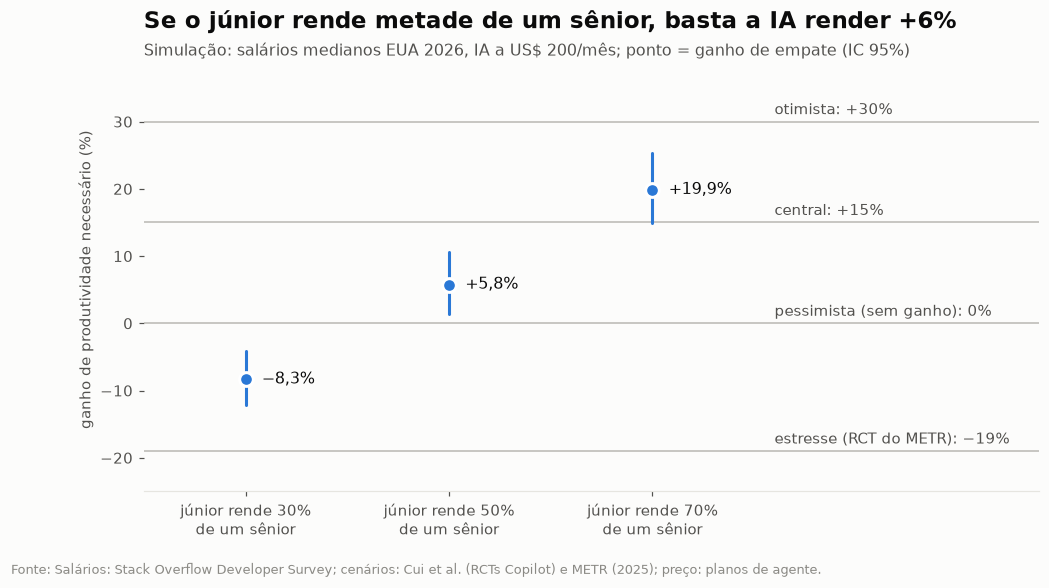

In [24]:
# Gráfico 7: ganho necessário (u*) vs. cenários de produtividade.
cen = be_p.drop_duplicates("cenario").set_index("cenario").ganho * 100
sens = H2["numeros"]["u_star_por_prod_jr"][str(ano_sal)]
pj = sorted(sens, key=float)
fig, ax = plt.subplots(figsize=(10.5, 5))
rot_cen = {"otimista": "otimista", "central": "central", "pessimista": "pessimista (sem ganho)",
           "estresse_METR": "estresse (RCT do METR)"}
for nome, v in cen.items():
    ax.axhline(v, color=CONTEXTO, lw=1)
    ax.text(len(pj) - 0.4, v + 0.6, f"{rot_cen.get(nome, nome)}: {pct(v, 0, True)}", fontsize=9.5, color=TEXTO_2,
            va="bottom")
for i, p in enumerate(pj):
    s = sens[p]
    est, lo, hi = s["estimativa"] * 100, s["ic_inf"] * 100, s["ic_sup"] * 100
    ax.plot([i, i], [lo, hi], color=DESTAQUE, lw=2, solid_capstyle="round")
    ax.plot(i, est, "o", color=DESTAQUE, ms=9, mec="white", mew=2)
    ax.text(i + 0.08, est, pct(est, 1, True), fontsize=10.5, color=TEXTO, va="center")
ax.set_xticks(range(len(pj)), [f"júnior rende {pct(float(p) * 100)}\nde um sênior" for p in pj])
ax.set_xlim(-0.5, len(pj) + 0.9)
ax.set_ylim(-25, 38)
ax.set_ylabel("ganho de produtividade necessário (%)")
ax.grid(axis="y", visible=False)
titulo(ax, f"Se o júnior rende metade de um sênior, basta a IA render {pct(u5, 0, True)}",
       f"Simulação: salários medianos EUA {ano_sal}, IA a US$ {num(be_p.custo_ia_ano.iloc[0] / 12)}/mês; ponto = ganho de empate (IC 95%)")
fonte(fig, "Salários: Stack Overflow Developer Survey; cenários: Cui et al. (RCTs Copilot) e METR (2025); preço: planos de agente.")
plt.show()

In [25]:
abaixo_central = [pct(float(p) * 100) for p in pj if sens[p]["estimativa"] * 100 < cen["central"]]
acima_central = [pct(float(p) * 100) for p in pj if sens[p]["estimativa"] * 100 >= cen["central"]]
mostrar(f"""
**O que vemos →** com o júnior rendendo {' ou '.join(abaixo_central)} de um sênior, o ganho de empate fica abaixo do cenário
central ({pct(cen['central'], 0, True)}); com {' ou '.join(acima_central) or 'nenhum'}, a IA precisaria render mais que isso.
Sem contar o teste de estresse, sênior + IA sai mais barato em {n_comp} das {n_tot} combinações. No estresse, em que a IA
atrasa o trabalho, não compensa em nenhuma.

**O que significa →** a conta favorece cortar o júnior, e os cenários vêm de estudos reais: RCTs de campo acharam
{lit('copilot_26')} a mais de tarefas concluídas com assistente de código ({cita('copilot_26', 'Cui et al.')}), enquanto devs
experientes de código aberto levaram {lit('metr_rct_19').split(' ')[0]} mais tempo com IA no estudo do METR ({cita('metr_rct_19', 'METR')}).
Veredito de H2: **{ICONE.get(H2['veredito'], H2['veredito'])}**: depende da premissa sobre quanto o júnior produz.
A conta deixa de fora o principal: o júnior de hoje é o sênior de amanhã.

**O que fazer →** gestor: a economia é real no curto prazo; a seção 7 mostra o custo que ela esconde.
""")


**O que vemos →** com o júnior rendendo 30% ou 50% de um sênior, o ganho de empate fica abaixo do cenário
central (+15%); com 70%, a IA precisaria render mais que isso.
Sem contar o teste de estresse, sênior + IA sai mais barato em 6 das 9 combinações. No estresse, em que a IA
atrasa o trabalho, não compensa em nenhuma.

**O que significa →** a conta favorece cortar o júnior, e os cenários vêm de estudos reais: RCTs de campo acharam
26,08% a mais de tarefas concluídas com assistente de código ([Cui et al.](https://economics.mit.edu/sites/default/files/inline-files/draft_copilot_experiments.pdf)), enquanto devs
experientes de código aberto levaram 19% mais tempo com IA no estudo do METR ([METR](https://metr.org/blog/2025-07-10-early-2025-ai-experienced-os-dev-study/)).
Veredito de H2: **◐ Parcial**: depende da premissa sobre quanto o júnior produz.
A conta deixa de fora o principal: o júnior de hoje é o sênior de amanhã.

**O que fazer →** gestor: a economia é real no curto prazo; a seção 7 mostra o custo que ela esconde.


## 6. Os modelos passaram nos testes de erro; a dúvida que sobra é de causa, não de ajuste
`CRISP-DM fase 5 | Avaliação`

In [26]:
bt = backtest.copy()
bt["melhor"] = np.where(bt.mape_modelo < bt.mape_ingenuo, "SARIMAX", "ingênuo")
tb = "| Origem | Erro SARIMAX (MAPE) | Erro ingênuo sazonal | Melhor |\n|---|---|---|---|\n" + "\n".join(
    f"| {mes_br(r.origem)} | {num(r.mape_modelo, 1)}% | {num(r.mape_ingenuo, 1)}% | {r.melhor} |" for r in bt.itertuples())
tp = "| Corte falso | Efeito médio em 12 meses | Meses seguidos abaixo do IC |\n|---|---|---|\n" + "\n".join(
    f"| {mes_br(r.corte_falso)} | {pct(r.efeito_pct_medio, 1, True)} | {r.meses_abaixo_ic_seguidos} |" for r in placebos.itertuples())
tp += f"\n| **ChatGPT (real), 12 meses** | **{pct(e12['efeito_pct_medio'], 1, True)}** | **{e12['meses_abaixo_ic_seguidos']}** |"
mostrar(f"""
**Backtest do Stack Overflow** (previsão de 12 meses a partir de cada origem, só com dados anteriores). O SARIMAX ganhou em
{A1['backtest']['origens_modelo_melhor']} de {A1['backtest']['n_origens']} origens e na média
({num(A1['backtest']['mape_modelo_medio'], 1)}% vs. {num(A1['backtest']['mape_ingenuo_medio'], 1)}%). A pior origem é a da COVID.

{tb}

**Placebos** (o mesmo modelo, fingindo que a IA chegou em outra data):

{tp}
""")


**Backtest do Stack Overflow** (previsão de 12 meses a partir de cada origem, só com dados anteriores). O SARIMAX ganhou em
4 de 6 origens e na média
(9,9% vs. 13,8%). A pior origem é a da COVID.

| Origem | Erro SARIMAX (MAPE) | Erro ingênuo sazonal | Melhor |
|---|---|---|---|
| out/2021 | 5,1% | 15,5% | SARIMAX |
| abr/2021 | 3,9% | 22,6% | SARIMAX |
| out/2020 | 9,0% | 19,3% | SARIMAX |
| abr/2020 | 28,1% | 11,1% | ingênuo |
| out/2019 | 8,3% | 7,6% | ingênuo |
| abr/2019 | 5,3% | 6,7% | SARIMAX |

**Placebos** (o mesmo modelo, fingindo que a IA chegou em outra data):

| Corte falso | Efeito médio em 12 meses | Meses seguidos abaixo do IC |
|---|---|---|
| jun/2019 | +22,1% | 0 |
| jun/2020 | −29,8% | 12 |
| **ChatGPT (real), 12 meses** | **−23,7%** | **7** |


In [27]:
lim = VS["limitacoes"] + [
    "Survey: quem responde se autosseleciona (é quem visita o Stack Overflow); não representa todos os programadores.",
    f"Survey: a amostra de 2026 é menor ({num(cob.loc[2026, 'n'])} respostas contra {num(cob.loc[2025, 'n'])} em 2025) e tem mais estudantes entre os iniciantes.",
    "Survey: a definição de 'usa agentes' mudou entre 2025 e 2026; só comparamos dentro do mesmo ano.",
    "Conta do gestor: só salário (sem encargos, mentoria, rotatividade) e produtividade de júnior por premissa.",
]
ver = [("Ato 1 · Stack Overflow", A1["veredito"]), ("Ato 2 · vagas", A2["veredito"]),
       ("H1 · primeiro degrau (survey)", H1["veredito"]), ("H2 · conta do gestor", H2["veredito"]),
       ("H3 · mercado mais exigente", H3["veredito"])]
mostrar("**Limitações**\n\n" + "\n".join(f"- {l}" for l in lim) +
        "\n\n**Veredito por hipótese**\n\n| Teste | Veredito |\n|---|---|\n" +
        "\n".join(f"| {a} | {ICONE.get(b, b)} |" for a, b in ver))

**Limitações**

- O Stack Overflow mede demanda por perguntas no site, não o 'primeiro degrau' da carreira; a queda também tem causas fora do mercado de trabalho (chatbots substituindo o Q&A, política de moderação, perguntas apagadas que não aparecem na API).
- O pré-período inclui o pico da COVID (2020): ele gera o placebo de 2020-06 (reversão do pico) e a pior origem do backtest.
- A ordem do SARIMAX é escolhida por AIC entre modelos com e sem diferença sazonal (D=0 vs. D=1); AICs com diferenciações diferentes não são estritamente comparáveis.
- Vagas (Indeed) só existem desde 2020-02: o pré-período tem 34 meses e é dominado pelo boom de software de 2021–22; FEDFUNDS e a dummy pós-ChatGPT são colineares (correlação ≈ 0,93) e um único juro é controle grosseiro do ciclo.
- Ato 2: os resíduos do OLS são fortemente autocorrelacionados (Durbin-Watson ≈ 0,2; lag-1 ≈ 0,9). Erros HAC com ~80 meses não corrigem isso; o teste usado no veredito é a regressão com erros AR(1). As regressões de robustez (diferença, vs. total, capacidade) e as checagens pós-hoc seguem em OLS+HAC e têm o mesmo problema.
- Escolha de método: na variante sazonal sem diferença sazonal (1,0,0,12) o SARIMAX leva deriva (trend='t', crescimento % constante com d=1); sem ela a previsão ficaria plana numa série que já caía, inflando o efeito.
- `previsto` no contrafactual é exp da média em log, ou seja, a mediana da previsão em nível (não a média); os limites lo95/hi95 são exp dos limites em log.
- ITS: o termo de mudança de nível (+27%, não significativo) é um desajuste de forma funcional — a queda acelera em termos de log, e a mudança de inclinação absorve a quebra; não ler o nível como 'alta'.
- Survey: quem responde se autosseleciona (é quem visita o Stack Overflow); não representa todos os programadores.
- Survey: a amostra de 2026 é menor (30.903 respostas contra 49.191 em 2025) e tem mais estudantes entre os iniciantes.
- Survey: a definição de 'usa agentes' mudou entre 2025 e 2026; só comparamos dentro do mesmo ano.
- Conta do gestor: só salário (sem encargos, mentoria, rotatividade) e produtividade de júnior por premissa.

**Veredito por hipótese**

| Teste | Veredito |
|---|---|
| Ato 1 · Stack Overflow | ◌ Inconclusivo |
| Ato 2 · vagas | ○ Consistente com ciclo |
| H1 · primeiro degrau (survey) | ● Confirmada |
| H2 · conta do gestor | ◐ Parcial |
| H3 · mercado mais exigente | ◐ Parcial |

## 7. Para quem está entrando, o degrau ficou mais alto; para quem contrata, cortá-lo sai caro depois
`CRISP-DM fase 6 | Implantação` · `Data Storytelling → decisão`

In [28]:
mostrar(f"""
**Para o estudante.** O degrau de entrada passou a cobrar o que antes se aprendia nele. Entre 2025 e 2026 a fatia empregada
de quem tem até 2 anos caiu {num(jr_max)} a {num(jr_min)} pontos, e o salário de entrada perdeu terreno para o do sênior.

- Fundamentos fortes (estrutura de dados, depuração, arquitetura): é o que permite julgar o código que o agente escreve.
- Domínio de agentes de IA como ferramenta de trabalho, sabendo que isso é requisito, não proteção.
- Portfólio que mostre entrega real: projeto em produção, contribuição em código aberto, estágio.
- Entradas alternativas: estágio, open source, áreas vizinhas (dados, QA, suporte técnico) como ponte.

**Para o gestor.** Hoje a conta fecha para "sênior + IA" em {n_comp} de {n_tot} cenários (fora o teste de estresse). Só que todo sênior já foi júnior:
cortar a entrada economiza agora e seca a fonte de sêniores daqui a alguns anos, quando eles ficarão mais caros (a razão
salarial já subiu para {num(g.loc[a1, 'razao_sr_jr'], 1)}×).

- Manter um pipeline júnior menor e intencional: aprendiz + IA + mentoria com meta de entrega.
- Medir o júnior pelo que ele entrega com IA, não por horas de tarefa simples que o agente já faz.

**KPIs para monitorar**

| Indicador | Fonte | Sinal de que a tese se fortalece |
|---|---|---|
| Vagas de software vs. mediana dos setores | Indeed Hiring Lab | software não acompanha a recuperação quando os juros caírem |
| % empregado ≤2 anos vs. ≥10 anos | Survey 2027 | a distância entre júnior e sênior persiste |
| Razão salarial sênior/júnior (EUA) | Survey 2027 | continua subindo |
| Horizonte de tarefa METR | Epoch AI / METR | segue dobrando a cada poucos meses |

**Como atualizar:** `python -m src.etl.stackoverflow` (e `survey`, `indeed`, `fred`, `capacidade`), depois
`python -m src.models.run_series` e `python -m src.models.run_survey`, e executar este notebook de novo
(ou pôr `RECALCULAR = True` na primeira célula).

**O ciclo continua.** Negócio → Dados → Preparação → Modelagem → Avaliação → Implantação → e de volta ao Negócio quando o
survey de 2027 sair. A pergunta das vagas, que os dados de hoje não resolvem, é a primeira a revisitar.
""")


**Para o estudante.** O degrau de entrada passou a cobrar o que antes se aprendia nele. Entre 2025 e 2026 a fatia empregada
de quem tem até 2 anos caiu 9 a 20 pontos, e o salário de entrada perdeu terreno para o do sênior.

- Fundamentos fortes (estrutura de dados, depuração, arquitetura): é o que permite julgar o código que o agente escreve.
- Domínio de agentes de IA como ferramenta de trabalho, sabendo que isso é requisito, não proteção.
- Portfólio que mostre entrega real: projeto em produção, contribuição em código aberto, estágio.
- Entradas alternativas: estágio, open source, áreas vizinhas (dados, QA, suporte técnico) como ponte.

**Para o gestor.** Hoje a conta fecha para "sênior + IA" em 6 de 9 cenários (fora o teste de estresse). Só que todo sênior já foi júnior:
cortar a entrada economiza agora e seca a fonte de sêniores daqui a alguns anos, quando eles ficarão mais caros (a razão
salarial já subiu para 2,3×).

- Manter um pipeline júnior menor e intencional: aprendiz + IA + mentoria com meta de entrega.
- Medir o júnior pelo que ele entrega com IA, não por horas de tarefa simples que o agente já faz.

**KPIs para monitorar**

| Indicador | Fonte | Sinal de que a tese se fortalece |
|---|---|---|
| Vagas de software vs. mediana dos setores | Indeed Hiring Lab | software não acompanha a recuperação quando os juros caírem |
| % empregado ≤2 anos vs. ≥10 anos | Survey 2027 | a distância entre júnior e sênior persiste |
| Razão salarial sênior/júnior (EUA) | Survey 2027 | continua subindo |
| Horizonte de tarefa METR | Epoch AI / METR | segue dobrando a cada poucos meses |

**Como atualizar:** `python -m src.etl.stackoverflow` (e `survey`, `indeed`, `fred`, `capacidade`), depois
`python -m src.models.run_series` e `python -m src.models.run_survey`, e executar este notebook de novo
(ou pôr `RECALCULAR = True` na primeira célula).

**O ciclo continua.** Negócio → Dados → Preparação → Modelagem → Avaliação → Implantação → e de volta ao Negócio quando o
survey de 2027 sair. A pergunta das vagas, que os dados de hoje não resolvem, é a primeira a revisitar.


---
## Apêndice
### A. Detalhes técnicos

In [29]:
mo = A1["modelo"]; s12 = A1["sensibilidade_inicio_2012"]
ordem = lambda m: f"SARIMAX{tuple(m['order'])}×{tuple(m['seasonal_order'])}, tendência '{m['trend']}'"
its = ITS
mostrar(f"""
**Ato 1, SARIMAX.** Log das perguntas mensais; treino {mes_br(mo['treino_inicio'])} a {mes_br(mo['treino_fim'])}
({mo['n_treino']} meses). Ordem escolhida por AIC: {ordem(mo)} (AIC = {num(mo['aic'], 1)}).
Sensibilidade com treino desde 2012: {ordem(s12['modelo'])}, efeito médio {pct(s12['efeito']['efeito_pct_medio'], 1)}
(quase igual ao principal, {pct(e48['efeito_pct_medio'], 1)}).

**Ato 1, ITS (regressão segmentada, erros {its['cov_type']}).** {its['n']} meses, R² = {num(its['r2'], 3)}.
Mudança de nível em dez/2022: {pct(its['nivel_pos']['efeito_pct'], 1, True)} (p = {num(its['nivel_pos']['p'], 2)}, não significativa).
Mudança de inclinação: {pct(its['inclinacao_pos']['efeito_pct'], 1, True)} ao mês (p < 0,001). A série não cai de uma vez;
ela passa a cair mais rápido todo mês.

**Ato 2, robustez.** Diferença em pontos de índice, software vs. índice total do Indeed e capacidade da IA (log do
horizonte METR) no lugar do marcador: p = {num(VAGAS['diferenca']['p_termo'], 4)}, {num(VAGAS['vs_total']['p_termo'], 6)} e
{num(VAGAS['capacidade']['p_termo'], 3)}, todos com erros HAC (sem a correção AR(1) do modelo principal).
""")


**Ato 1, SARIMAX.** Log das perguntas mensais; treino jan/2014 a out/2022
(106 meses). Ordem escolhida por AIC: SARIMAX(0, 1, 2)×(1, 0, 0, 12), tendência 't' (AIC = −282,2).
Sensibilidade com treino desde 2012: SARIMAX(1, 1, 0)×(1, 0, 0, 12), tendência 't', efeito médio −64,7%
(quase igual ao principal, −64,4%).

**Ato 1, ITS (regressão segmentada, erros HAC (Newey-West), maxlags=12).** 154 meses, R² = 0,984.
Mudança de nível em dez/2022: +27,0% (p = 0,27, não significativa).
Mudança de inclinação: −9,3% ao mês (p < 0,001). A série não cai de uma vez;
ela passa a cair mais rápido todo mês.

**Ato 2, robustez.** Diferença em pontos de índice, software vs. índice total do Indeed e capacidade da IA (log do
horizonte METR) no lugar do marcador: p = 0,0007, 0,000003 e
0,078, todos com erros HAC (sem a correção AR(1) do modelo principal).



**Classificador de ameaça (H3).** Survey 2025, 36.078 respostas. split 80/20 estratificado; StratifiedKFold(5, shuffle, seed) só no treino; modelo escolhido pela AUC de CV no treino.
Variáveis: faixa_exp, cargo, pais, usa_agentes, ia_usa, emprego. AUC no conjunto de teste: 0,603.

| Modelo | AUC (CV, média ± dp) | F1 |
|---|---|---|
| Trivial (sempre a classe mais comum) | 0,500 ± 0,000 | 0,000 |
| Logística só com experiência | 0,513 ± 0,008 | 0,162 |
| Logística com todas as variáveis | 0,609 ± 0,010 | 0,292 |
| HistGradientBoosting | 0,604 ± 0,008 | 0,292 |


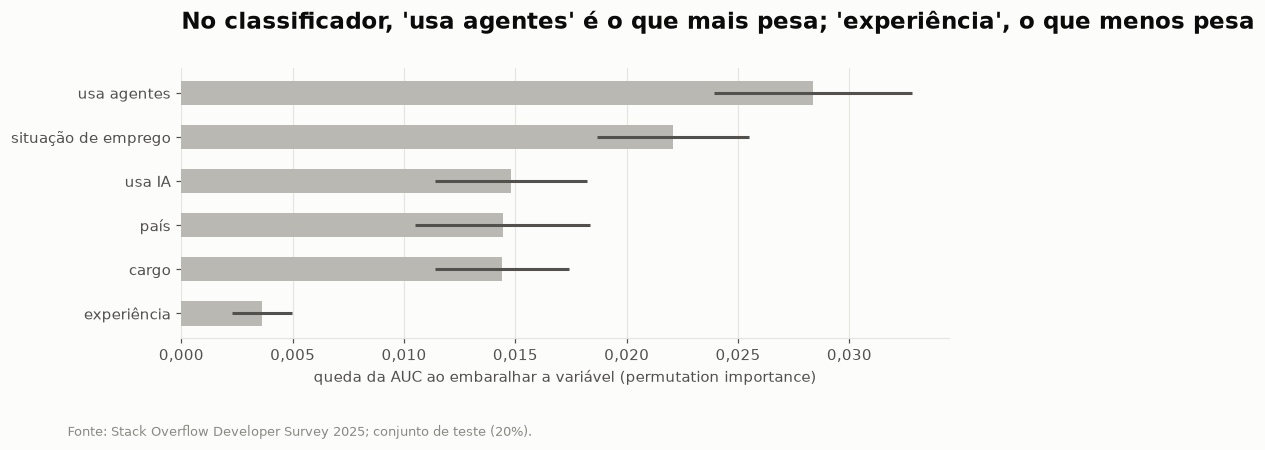

In [30]:
mt = CLF["metricas"]
nm = {"dummy": "Trivial (sempre a classe mais comum)", "logistica_so_faixa_exp": "Logística só com experiência",
      "logistica": "Logística com todas as variáveis", "hgb": "HistGradientBoosting"}
tc = "| Modelo | AUC (CV, média ± dp) | F1 |\n|---|---|---|\n" + "\n".join(
    f"| {nm.get(k, k)} | {num(v['auc_media'], 3)} ± {num(v['auc_dp'], 3)} | {num(v['f1_media'], 3)} |" for k, v in mt.items())
mostrar(f"""
**Classificador de ameaça (H3).** Survey {CLF['ano']}, {num(CLF['n'])} respostas. {CLF['cv']}.
Variáveis: {', '.join(CLF['features'])}. AUC no conjunto de teste: {num(CLF['auc_holdout'], 3)}.

{tc}
""")
fig, ax = plt.subplots(figsize=(9, 3.6))
fig.subplots_adjust(bottom=0.2)
ax.set_axisbelow(True)
nomes_f = {"usa_agentes": "usa agentes", "emprego": "situação de emprego", "ia_usa": "usa IA", "pais": "país",
           "cargo": "cargo", "faixa_exp": "experiência"}
ii = imp.sort_values("importancia_media")
ax.barh(ii.feature.map(nomes_f).fillna(ii.feature), ii.importancia_media, xerr=ii.importancia_dp, color=CONTEXTO,
        ecolor=TEXTO_2, height=0.55)
virgula(ax, "x", 3)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("queda da AUC ao embaralhar a variável (permutation importance)")
top, low = ii.feature.iloc[-1], ii.feature.iloc[0]
titulo(ax, f"No classificador, '{nomes_f.get(top, top)}' é o que mais pesa; '{nomes_f.get(low, low)}', o que menos pesa")
fonte(fig, f"Stack Overflow Developer Survey {CLF['ano']}; conjunto de teste (20%).")
plt.show()

In [31]:
mostrar("**Reprodutibilidade.** `pip install -r requirements.txt`; chave da Stack Exchange API no `.env` (veja `.env.example`); "
        "rodar o ETL e os modelos (seção 7); executar este notebook de cima a baixo. O notebook lê só `data/processed/` e "
        "`data/results/` e não acessa a rede.")

**Reprodutibilidade.** `pip install -r requirements.txt`; chave da Stack Exchange API no `.env` (veja `.env.example`); rodar o ETL e os modelos (seção 7); executar este notebook de cima a baixo. O notebook lê só `data/processed/` e `data/results/` e não acessa a rede.

### B. Referências

Todas as referências abaixo foram abertas na fonte primária em 26/11/2026 (data de acesso). Os números conferidos estão em `data/processed/fatos_literatura.csv`.

#### Mercado de trabalho

BRYNJOLFSSON, Erik; CHANDAR, Bharat; CHEN, Ruyu. **Canaries in the Coal Mine? Six Facts about the Recent Employment Effects of Artificial Intelligence**. Stanford Digital Economy Lab; NBER, ago. 2026 (versão com dados até jun. 2026; primeira versão ago. 2025). Disponível em: <https://digitaleconomy.stanford.edu/app/uploads/2026/08/Canaries_August2026.pdf>. Acesso em: 26 nov. 2026.

HOSSEINI, Seyed M.; LICHTINGER, Guy. **Generative AI as Seniority-Biased Technological Change: Evidence from U.S. Résumé and Job Posting Data**. Harvard University, versão de 6 maio 2026 (primeira versão 31 ago. 2025). SSRN 5425555. Disponível em: <https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5425555>. Acesso em: 26 nov. 2026. (Valores lidos no PDF do rascunho de mai. 2026: <https://raw.githack.com/s-mahdihosseini/Website/b99fa2962dcc4c165bbc3c41dd283afa99c5ccfb/GenAI_SenBTC_May_2026.pdf>.)

GALLACHER, Guillermo. **AI and Job Postings: From Destruction to Creation?** Indeed Hiring Lab, 8 jul. 2026. Disponível em: <https://hiringlab.indeed.com/?p=20708>. Acesso em: 26 nov. 2026.

DEL RIO-CHANONA, R. Maria; LAURENTSYEVA, Nadzeya; WACHS, Johannes. Large language models reduce public knowledge sharing on online Q&A platforms. **PNAS Nexus**, v. 3, n. 9, pgae400, 11 set. 2024. DOI: 10.1093/pnasnexus/pgae400. Disponível em: <https://pmc.ncbi.nlm.nih.gov/articles/PMC11421660/>. Acesso em: 26 nov. 2026.

#### Produtividade

CUI, Kevin Zheyuan; DEMIRER, Mert; JAFFE, Sonia; MUSOLFF, Leon; PENG, Sida; SALZ, Tobias. The Effects of Generative AI on High-Skilled Work: Evidence from Three Field Experiments with Software Developers. **Management Science**, 2025. DOI: 10.1287/mnsc.2025.00535. Disponível em: <https://pubsonline.informs.org/doi/10.1287/mnsc.2025.00535>. Acesso em: 26 nov. 2026. (Números conferidos no rascunho de fev. 2025: <https://economics.mit.edu/sites/default/files/inline-files/draft_copilot_experiments.pdf>.)

METR. **Measuring the Impact of Early-2025 AI on Experienced Open-Source Developer Productivity**. 10 jul. 2025. Disponível em: <https://metr.org/blog/2025-07-10-early-2025-ai-experienced-os-dev-study/>. Acesso em: 26 nov. 2026. Artigo: arXiv:2507.09089, <https://arxiv.org/abs/2507.09089>.

METR. **Uplift update** (atualização do estudo de produtividade). 24 fev. 2026. Disponível em: <https://metr.org/blog/2026-02-24-uplift-update/>. Acesso em: 26 nov. 2026.

#### Capacidade da IA

KWA, Thomas et al. **Measuring AI Ability to Complete Long Software Tasks** (título atual do arXiv; primeira versão: "Measuring AI Ability to Complete Long Tasks"). arXiv:2503.14499, mar. 2025 (v4 em 10 jul. 2026). Disponível em: <https://arxiv.org/abs/2503.14499>. Acesso em: 26 nov. 2026.

METR. **Time Horizon 1.1**. 29 jan. 2026. Disponível em: <https://metr.org/blog/2026-01-29-time-horizon-1-1/>. Acesso em: 26 nov. 2026.

METR. **Task-Completion Time Horizons of Frontier AI Models**. Disponível em: <https://metr.org/time-horizons/>. Acesso em: 26 nov. 2026.

VALS.AI. **SWE-bench** (benchmark arquivado por saturação; topo de 97,00% em 1 set. 2026). Disponível em: <https://www.vals.ai/benchmarks/swebench>. Acesso em: 26 nov. 2026.

EPOCH AI. **SWE-bench Verified**. Disponível em: <https://epoch.ai/benchmarks/swe-bench-verified>. Acesso em: 26 nov. 2026.

#### Preços de ferramentas de IA (premissa H2)

ANTHROPIC. **Planos e preços do Claude**. Disponível em: <https://claude.com/pricing>. Acesso em: 26 nov. 2026.

ANTHROPIC. **What is the Ultra plan?** Claude Help Center. Disponível em: <https://support.claude.com/en/articles/17728952-what-is-the-ultra-plan>. Acesso em: 26 nov. 2026.

OPENAI. **About ChatGPT Pro tiers**. OpenAI Help Center. Disponível em: <https://help.openai.com/en/articles/9793128-about-chatgpt-pro-tiers>. Acesso em: 26 nov. 2026.

CURSOR (ANYSPHERE). **Pricing**. Disponível em: <https://cursor.com/pricing>. Acesso em: 26 nov. 2026.

#### Observações de verificação

- Não foi encontrada em fonte primária a queda de "quase 20%" dos desenvolvedores de 22-25 anos (Canaries); ela não consta na versão de ago. 2026 e só aparece em fontes secundárias. O texto deve usar os 19% gerais.
- Não foi confirmado o horizonte METR "acima de 8 h" para modelos de 2026 (valores só no gráfico/YAML).